# Dominik: Wyszukiwanie hybrydowe i re-ranking (Część I, pkt 4-5)

Zakres (3 pkt): pkt 4 i 5 z [instrukcji](../Zadanie_3_zmodyfikowane.md).

**Zależność od Piotrka:** zbiór dokumentów, zapytania, osadzenia, indeks FAISS i metryki pochodzą z `../utils/` (patrz [README](../README.md)), więc wyniki są wprost porównywalne z pkt 3. Moje dodatki w `utils/` używają tego samego formatu rankingów `{query_id: [(doc_id, score), ...]}`:

| Moduł | Funkcja | Punkt |
|---|---|---|
| `utils/lexical.py` | `build_bm25`, `search_bm25` | 4.a |
| `utils/fusion.py` | `reciprocal_rank_fusion` | 4.b |
| `utils/rerank.py` | `rerank` (cross-enkoder) | 5 |

Wspólny wariant ewaluacji: `top_k = 5`, 500 zapytań (ziarno 42), 18 891 dokumentów po deduplikacji, metryki Recall@5, MRR@5, nDCG@5.

Dziennik decyzji: [NOTATKI.md](NOTATKI.md). Uzasadnienie wielkości puli re-rankingu: [rerank_pool.md](rerank_pool.md).

In [1]:
import os
import re
import sys
import time
from collections import Counter, defaultdict

# Bez pasków postępu (pobieranie modeli, kodowanie) w zapisanych wyjściach notebooka.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TQDM_DISABLE"] = "1"
sys.path.insert(0, "..")

import bm25s
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import Stemmer
from IPython.display import display
from matplotlib_venn import venn2

from utils import (
    build_bm25,
    build_faiss_index,
    encode_corpus_and_queries,
    evaluate_rankings,
    get_cross_encoder,
    get_model,
    load_squad_data,
    reciprocal_rank_fusion,
    rerank,
    search_bm25,
    search_faiss,
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_colwidth", 120)

TOP_K = 5          # wspólny wariant ewaluacji
DEPTH = 100        # długość list BM25 i bi-enkodera przed fuzją (Q5)
RRF_K = 60         # stała k w RRF (instrukcja)
CE_TOP_N = 50      # liczba kandydatów hybrydy oceniana przez cross-enkoder (Q7)
CE_MODEL = "cross-encoder/ms-marco-MiniLM-L6-v2"
CE_MODEL_L12 = "cross-encoder/ms-marco-MiniLM-L12-v2"
ARTIFACTS = "../artifacts"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Każdy system ma jeden kolor we wszystkich wykresach.
MUTED = sns.color_palette("muted")
COLORS = {
    "BM25": MUTED[1],
    "Bi-enkoder": MUTED[0],
    "Hybryda RRF": MUTED[2],
    "Hybryda + CE (top-5)": MUTED[4],
    "Hybryda + CE (top-50)": MUTED[3],
    "Hybryda + CE L12 (top-50)": MUTED[5],
}
METRICS = [f"Recall@{TOP_K}", f"MRR@{TOP_K}", f"nDCG@{TOP_K}"]
LATENCY_MS = {}  # średni czas na zapytanie [ms], bez ładowania modeli


def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")


def timed(fn, *args, **kwargs):
    t0 = time.perf_counter()
    result = fn(*args, **kwargs)
    return result, time.perf_counter() - t0


def gold_ranks(rankings, qrels):
    # Pozycja (od 1) pierwszego relewantnego dokumentu na liście albo None.
    out = {}
    for q_id, rel_docs in qrels.items():
        rel = set(rel_docs)
        out[q_id] = next(
            (rank for rank, (doc_id, _) in enumerate(rankings.get(q_id, []), start=1) if doc_id in rel),
            None,
        )
    return out


def truncate(rankings, n):
    return {q_id: ranked[:n] for q_id, ranked in rankings.items()}

## 0. Dane i bi-enkoder z pkt 3

Ładuję dane i osadzenia przez `utils` Piotrka bez zmian (domyślnie split `train`, który jest jedynym splitem `sentence-transformers/squad`). Bi-enkoder (`multi-qa-mpnet-base-dot-v1` + FAISS `IndexFlatIP`) zwraca tu **top-100** zamiast top-5: dłuższe listy są potrzebne do fuzji (4.b) i re-rankingu (5), a `evaluate_rankings(..., k=5)` i tak patrzy tylko na pierwsze 5 pozycji. Pierwszy assert sprawdza, że odtwarzam wynik Piotrka.

Czas bi-enkodera = zakodowanie zapytań (GPU) + przeszukanie FAISS, po rozgrzewce i bez ładowania modelu.

In [2]:
queries, docs, qrels = load_squad_data()
q_emb, d_emb = encode_corpus_and_queries(queries, docs)

doc_text = {d["doc_id"]: d["text"] for d in docs}
query_text = {q["query_id"]: q["text"] for q in queries}
print(f"Zapytania: {len(queries)}, dokumenty: {len(docs)}, osadzenia: {q_emb.shape} / {d_emb.shape}")

Zapytania: 500, dokumenty: 18891, osadzenia: (500, 768) / (18891, 768)


In [3]:
index = build_faiss_index(d_emb, save_path=f"{ARTIFACTS}/squad_faiss_flatip.index")

# Pomiar czasu: kodowanie zapytań + wyszukiwanie (osadzenia do wyszukiwania biorę z cache utils).
bi_model = get_model()
bi_model.encode(["rozgrzewka"] * 8, show_progress_bar=False)
_, t_encode = timed(bi_model.encode, [q["text"] for q in queries], batch_size=64, convert_to_numpy=True, show_progress_bar=False)
search_faiss(index, q_emb[:5], queries[:5], docs, top_k=DEPTH)
dense_100, t_search = timed(search_faiss, index, q_emb, queries, docs, top_k=DEPTH)
LATENCY_MS["Bi-enkoder"] = (t_encode + t_search) / len(queries) * 1000

m_dense = evaluate_rankings(dense_100, qrels, k=TOP_K)
print("Bi-enkoder:", {k: round(v, 4) for k, v in m_dense.items()}, f"| {LATENCY_MS['Bi-enkoder']:.2f} ms/zapytanie")

# Wynik Piotrka z pkt 3 (piotrek.ipynb). Tolerancja 0.005 ≈ 2 zapytania na 500:
# osadzenia liczone na innej karcie GPU mogą minimalnie zmienić kolejność remisów.
PIOTREK = {"Recall@5": 0.882, "MRR@5": 0.751733, "nDCG@5": 0.784511}
for name, ref in PIOTREK.items():
    assert abs(m_dense[name] - ref) < 0.005, (name, m_dense[name], ref)
print("OK: wynik bi-enkodera zgodny z pkt 3")

Bi-enkoder: {'Recall@5': 0.882, 'MRR@5': 0.7517, 'nDCG@5': 0.7845} | 0.88 ms/zapytanie
OK: wynik bi-enkodera zgodny z pkt 3


## 4.a Wyszukiwanie leksykalne BM25

`bm25s` z tokenizacją: małe litery, angielskie stopwords, stemmer Snowball, `k1 = 1.5`, `b = 0.75` (bez strojenia na zbiorze testowym). `search_bm25` pomija dokumenty z wynikiem 0, bo `bm25s` dopełnia nimi listę do `top_k`, a nie mają z zapytaniem żadnego wspólnego termu.

Test poprawności: zapytanie będące dosłownym fragmentem akapitu (pierwsze 15 słów) powinno zwrócić ten akapit na pozycji 1.

In [4]:
bm25 = build_bm25(docs, cache_path=f"{ARTIFACTS}/bm25_squad")

search_bm25(bm25, queries[:5], docs, top_k=DEPTH)  # rozgrzewka
bm25_100, t_bm25 = timed(search_bm25, bm25, queries, docs, top_k=DEPTH)
LATENCY_MS["BM25"] = t_bm25 / len(queries) * 1000

m_bm25 = evaluate_rankings(bm25_100, qrels, k=TOP_K)
print("BM25:", {k: round(v, 4) for k, v in m_bm25.items()}, f"| {LATENCY_MS['BM25']:.2f} ms/zapytanie")
print(f"Zapytania z listą krótszą niż {DEPTH}: {sum(len(v) < DEPTH for v in bm25_100.values())}, "
      f"z pustą listą: {sum(not v for v in bm25_100.values())}")

# Test: dosłowny fragment akapitu -> ten akapit na pozycji 1.
rng = np.random.default_rng(42)
sample_pos = rng.choice(len(docs), size=50, replace=False)
frag_queries = [{"query_id": f"frag_{i}", "text": " ".join(docs[i]["text"].split()[:15])} for i in sample_pos]
frag_rankings = search_bm25(bm25, frag_queries, docs, top_k=1)
frag_hit = np.mean([frag_rankings[fq["query_id"]][0][0] == docs[i]["doc_id"] for fq, i in zip(frag_queries, sample_pos)])
print(f"Fragment akapitu -> akapit na pozycji 1: {frag_hit:.0%}")
assert frag_hit >= 0.95

BM25: {'Recall@5': 0.852, 'MRR@5': 0.7615, 'nDCG@5': 0.7843} | 1.17 ms/zapytanie
Zapytania z listą krótszą niż 100: 0, z pustą listą: 0
Fragment akapitu -> akapit na pozycji 1: 98%


## 4.b Reciprocal Rank Fusion (k = 60)

$$\mathrm{RRF}(d) = \sum_i \frac{1}{k + \mathrm{rank}_i(d)},\qquad k = 60,\ \mathrm{rank}_i \text{ liczone od } 1.$$

Łączę **pełne listy top-100** obu systemów i dopiero wynik fuzji przycinam do top-5. Fuzja samych list top-5 nie pozwoliłaby awansować dokumentowi, który np. w BM25 jest na 7. miejscu, a w bi-enkoderze na 3. Najpierw test na ręcznie policzonym przykładzie.

In [5]:
# Ręczny przykład: A = 1/61 + 1/62, C = 1/63 + 1/61, B = 1/62, D = 1/63.
toy_a = {"q": [("A", 9.0), ("B", 8.0), ("C", 7.0)]}
toy_b = {"q": [("C", 0.9), ("A", 0.5), ("D", 0.1)]}
toy = reciprocal_rank_fusion([toy_a, toy_b], k=60)
assert [d for d, _ in toy["q"]] == ["A", "C", "B", "D"]
assert np.isclose(toy["q"][0][1], 1 / 61 + 1 / 62) and np.isclose(toy["q"][1][1], 1 / 63 + 1 / 61)
print("OK: RRF zgodny z ręcznym przykładem")

hybrid_full, t_fuse = timed(reciprocal_rank_fusion, [bm25_100, dense_100], k=RRF_K)
LATENCY_MS["Hybryda RRF"] = LATENCY_MS["BM25"] + LATENCY_MS["Bi-enkoder"] + t_fuse / len(queries) * 1000
m_hybrid = evaluate_rankings(hybrid_full, qrels, k=TOP_K)
print("Hybryda RRF:", {k: round(v, 4) for k, v in m_hybrid.items()}, f"| {LATENCY_MS['Hybryda RRF']:.2f} ms/zapytanie")
print(f"Średnia długość listy po fuzji: {np.mean([len(v) for v in hybrid_full.values()]):.1f} dokumentów")

OK: RRF zgodny z ręcznym przykładem
Hybryda RRF: {'Recall@5': 0.91, 'MRR@5': 0.8165, 'nDCG@5': 0.84} | 2.11 ms/zapytanie
Średnia długość listy po fuzji: 173.6 dokumentów


### Wrażliwość na długość list przed fuzją

Ten sam RRF, ale obie listy wejściowe przycięte do N ∈ {5, 10, 20, 50, 100}. Linia przerywana to najlepszy pojedynczy system (bi-enkoder).

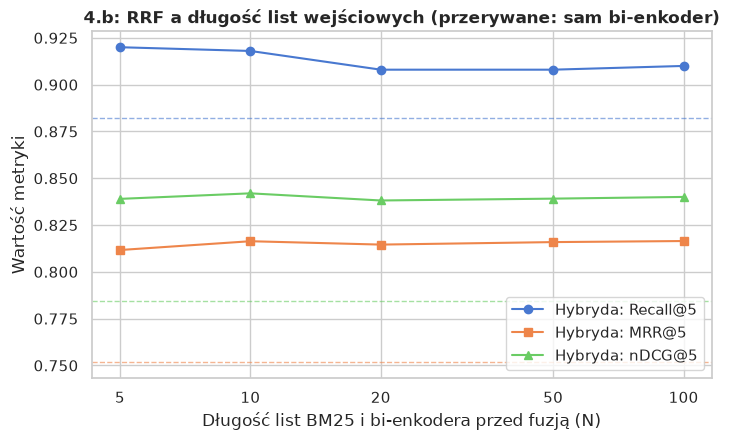

,N,Recall@5,MRR@5,nDCG@5
0,5,0.920,0.8117,0.8390
1,10,0.918,0.8164,0.8419
2,20,0.908,0.8146,0.8381
3,50,0.908,0.8159,0.8391
4,100,0.910,0.8165,0.8400


In [6]:
depth_rows = []
for n in [5, 10, 20, 50, 100]:
    fused = reciprocal_rank_fusion([truncate(bm25_100, n), truncate(dense_100, n)], k=RRF_K)
    depth_rows.append({"N": n, **evaluate_rankings(fused, qrels, k=TOP_K)})
df_depth = pd.DataFrame(depth_rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
for metric, marker in zip(METRICS, ["o", "s", "^"]):
    line, = ax.plot(df_depth["N"], df_depth[metric], marker=marker, label=f"Hybryda: {metric}")
    ax.axhline(m_dense[metric], ls="--", lw=1, color=line.get_color(), alpha=0.6)
ax.set_xscale("log")
ax.set_xticks(df_depth["N"], labels=df_depth["N"].astype(str))
ax.set_xlabel("Długość list BM25 i bi-enkodera przed fuzją (N)")
ax.set_ylabel("Wartość metryki")
ax.set_title("4.b: RRF a długość list wejściowych (przerywane: sam bi-enkoder)", fontweight="bold")
ax.legend(loc="lower right")
save_fig(fig, "4b_rrf_dlugosc_list")
plt.show()
display(df_depth.round(4))

**Wnioski (4.b).** Hybryda RRF poprawia wszystkie metryki względem najlepszego pojedynczego systemu: Recall@5 0.910 (+0.028 względem bi-enkodera), MRR@5 0.817 (+0.055 względem BM25), nDCG@5 0.840 (+0.055).

Długość list wejściowych ma mały wpływ: Recall@5 waha się w przedziale 0.908–0.920, a MRR@5 0.812–0.817, czyli o 3–6 zapytań na 500, w granicach szumu. Krótkie listy dają nieco wyższy Recall@5, długie nieco wyższe MRR@5. Przy k = 60 wkład pozycji spada łagodnie (1/61 dla 1. miejsca, 1/160 dla 100.), więc dokument na 30. miejscu **obu** list (2/90 ≈ 0.022) wyprzedza dokument na 1. miejscu tylko jednej listy (1/61 ≈ 0.016). Czasem to pomaga, czasem wpuszcza do top-5 szum z głębi list. Zostaję przy N = 100, bo listy top-100 i tak są potrzebne jako pula kandydatów do re-rankingu (pkt 5).

## 4.c Porównanie BM25, bi-enkodera i hybrydy (top_k = 5)

Wykres po lewej: metryki. Po prawej: dla ilu zapytań złoty dokument jest w top-5 każdego z systemów. Część wspólna pokazuje, jak bardzo systemy się pokrywają, a części rozłączne to potencjał hybrydy.

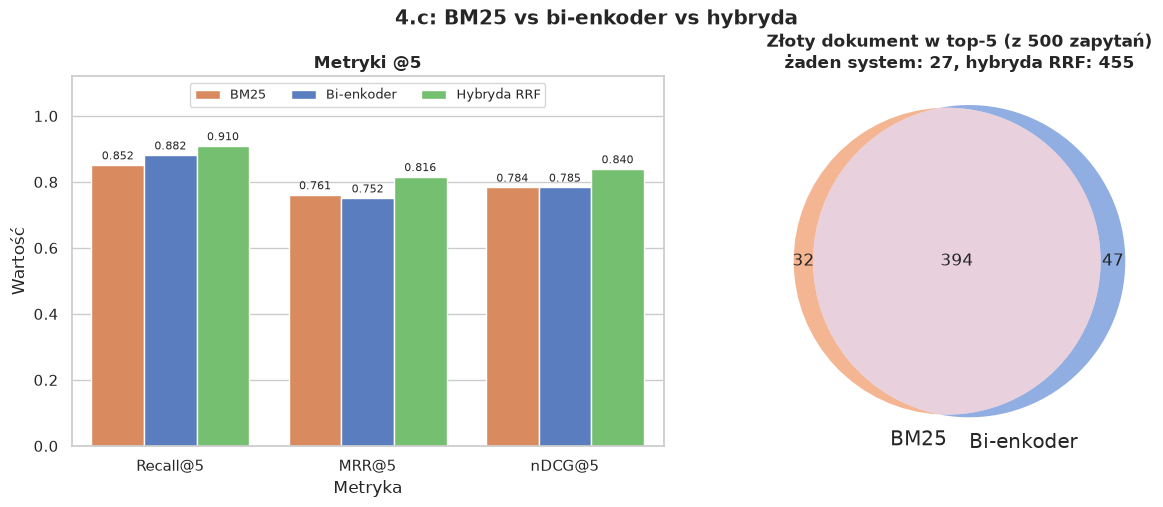

,Recall@5,MRR@5,nDCG@5
System,,,
BM25,0.852,0.7615,0.7843
Bi-enkoder,0.882,0.7517,0.7845
Hybryda RRF,0.910,0.8165,0.8400


Tylko BM25: 32, tylko bi-enkoder: 47, oba: 394
Hybryda odzyskuje 56 z 79 zapytań trafionych tylko przez jeden system; traci 0 trafionych przez oba


In [7]:
SYS3 = {"BM25": bm25_100, "Bi-enkoder": dense_100, "Hybryda RRF": hybrid_full}
df_3 = pd.DataFrame([{"System": name, **evaluate_rankings(r, qrels, k=TOP_K)} for name, r in SYS3.items()])

rank_bm25 = gold_ranks(bm25_100, qrels)
rank_dense = gold_ranks(dense_100, qrels)
rank_hybrid = gold_ranks(hybrid_full, qrels)


def in_top(rank, k=TOP_K):
    return rank is not None and rank <= k


hits_bm25 = {q for q, r in rank_bm25.items() if in_top(r)}
hits_dense = {q for q, r in rank_dense.items() if in_top(r)}
hits_hybrid = {q for q, r in rank_hybrid.items() if in_top(r)}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
long = df_3.melt(id_vars="System", var_name="Metryka", value_name="Wartość")
sns.barplot(data=long, x="Metryka", y="Wartość", hue="System", palette=COLORS, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=8, padding=2)
axes[0].set_ylim(0, 1.12)
axes[0].set_title("Metryki @5", fontweight="bold")
axes[0].legend(loc="upper center", ncol=3, fontsize=9)

v = venn2([hits_bm25, hits_dense], set_labels=("BM25", "Bi-enkoder"),
          set_colors=(COLORS["BM25"], COLORS["Bi-enkoder"]), alpha=0.6, ax=axes[1])
missed_both = len(qrels) - len(hits_bm25 | hits_dense)
axes[1].set_title(
    f"Złoty dokument w top-5 (z {len(qrels)} zapytań)\n"
    f"żaden system: {missed_both}, hybryda RRF: {len(hits_hybrid)}",
    fontweight="bold",
)
fig.suptitle("4.c: BM25 vs bi-enkoder vs hybryda", fontweight="bold", y=1.02)
save_fig(fig, "4c_porownanie")
plt.show()
display(df_3.set_index("System").round(4))
print(f"Tylko BM25: {len(hits_bm25 - hits_dense)}, tylko bi-enkoder: {len(hits_dense - hits_bm25)}, oba: {len(hits_bm25 & hits_dense)}")
print(f"Hybryda odzyskuje {len(hits_hybrid & (hits_bm25 ^ hits_dense))} z {len(hits_bm25 ^ hits_dense)} zapytań trafionych tylko przez jeden system; "
      f"traci {len((hits_bm25 & hits_dense) - hits_hybrid)} trafionych przez oba")

**Wnioski (4.c).** BM25 i bi-enkoder mają prawie identyczne nDCG@5 (0.784 vs 0.785), ale inny profil błędów:
- BM25 częściej trafia na **1. miejsce** (MRR@5 0.761 vs 0.752, Recall@1 0.698 vs 0.666 na wykresie 5.c (2)),
- bi-enkoder częściej ma złoty akapit **gdzieś w top-5** (Recall@5 0.882 vs 0.852).

SQuAD sprzyja BM25 bardziej niż typowe wyszukiwanie: annotatorzy pisali pytania, patrząc na akapit, więc często powtarzają jego słowa.

Diagram Venna pokazuje, że błędy są w dużej mierze rozłączne: 394 zapytania trafiają oba systemy, 32 tylko BM25, 47 tylko bi-enkoder, a 27 żaden. To jest cały potencjał hybrydy. RRF odzyskuje 56 z 79 zapytań trafionych przez jeden system i nie traci żadnego trafionego przez oba (455 trafień w top-5 vs 441 dla bi-enkodera).

## 4.d Zapytania, dla których lepiej działa wyszukiwanie leksykalne vs gęste

Dzielę zapytania na koszyki według tego, który system ma złoty dokument w top-5: **tylko BM25**, **tylko bi-enkoder**, **oba**, **żaden**. Dla każdego zapytania liczę proste cechy, żeby hipotezę z instrukcji (BM25: nazwy własne, liczby, rzadkie terminy; gęste: parafrazy, synonimy) sprawdzić liczbami, a nie tylko na przykładach:

- **liczba**: czy zapytanie zawiera cyfrę,
- **nazwy własne**: liczba słów z wielkiej litery poza pierwszym słowem,
- **średnie IDF**: średnia rzadkość termów zapytania w korpusie (wysoka = rzadkie terminy),
- **pokrycie leksykalne**: jaka część termów zapytania (po stemmingu, bez stopwords) występuje w złotym akapicie (niska = parafraza).

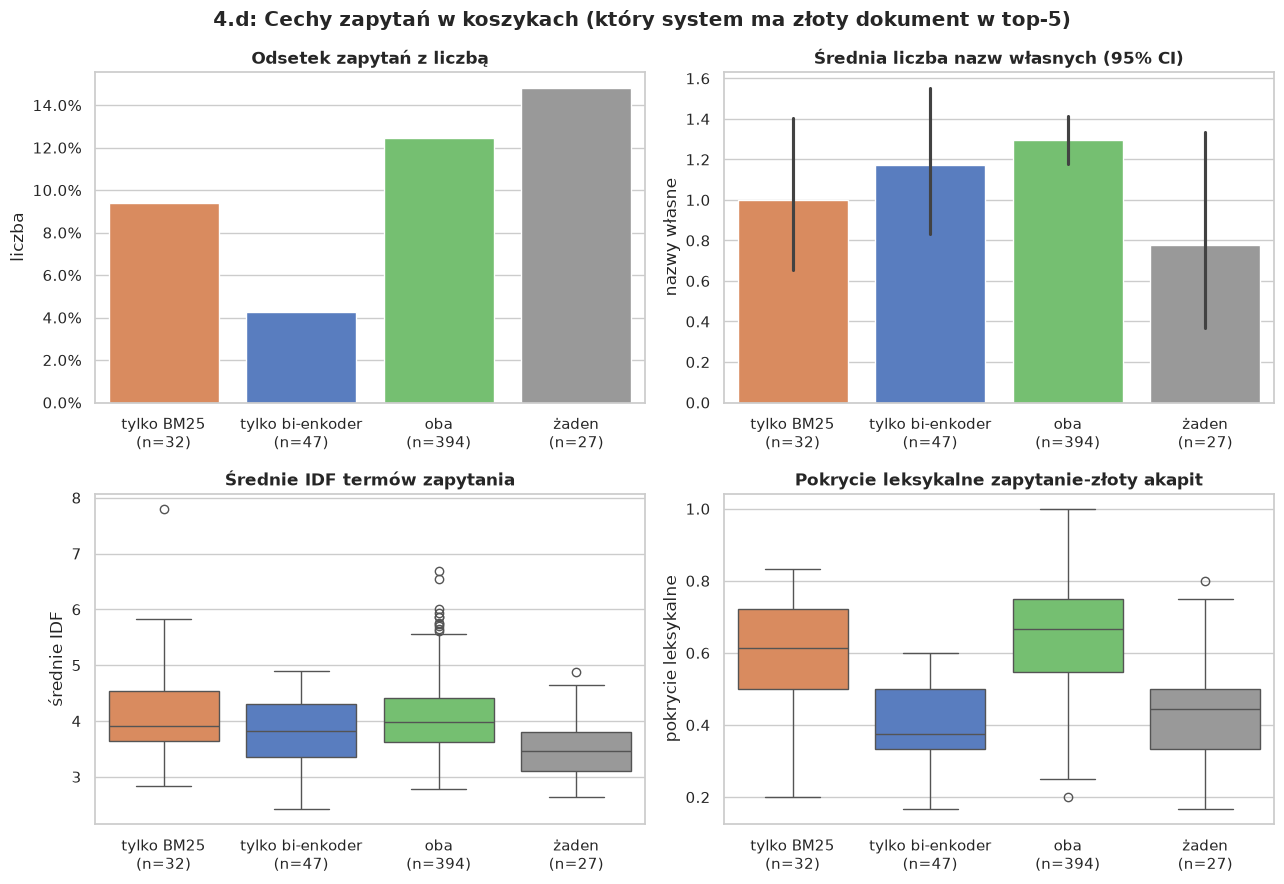

,n,liczba,nazwy_wlasne,srednie_idf,pokrycie
koszyk,,,,,
tylko BM25,32,0.094,1.000,4.210,0.600
tylko bi-enkoder,47,0.043,1.170,3.819,0.386
oba,394,0.124,1.294,4.071,0.651
żaden,27,0.148,0.778,3.556,0.442


In [8]:
stemmer = Stemmer.Stemmer("english")
tok = lambda texts: bm25s.tokenize(texts, stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)

doc_tokens = tok([d["text"] for d in docs])
doc_tokset = {d["doc_id"]: set(t) for d, t in zip(docs, doc_tokens)}
df_counts = Counter(t for toks in doc_tokens for t in set(toks))
N_DOCS = len(docs)


def idf(term):
    n = df_counts.get(term, 0)
    return np.log((N_DOCS - n + 0.5) / (n + 0.5) + 1)


def bucket(q_id):
    b, d = q_id in hits_bm25, q_id in hits_dense
    return "oba" if b and d else "tylko BM25" if b else "tylko bi-enkoder" if d else "żaden"


BUCKETS = ["tylko BM25", "tylko bi-enkoder", "oba", "żaden"]
rows = []
for q, q_toks in zip(queries, tok([q["text"] for q in queries])):
    q_id, text = q["query_id"], q["text"]
    words = re.findall(r"[A-Za-z][\w'-]*", text)
    terms = set(q_toks)
    gold = qrels[q_id][0]
    rows.append({
        "query_id": q_id,
        "koszyk": bucket(q_id),
        "liczba": bool(re.search(r"\d", text)),
        "nazwy własne": sum(w[0].isupper() for w in words[1:]),
        "średnie IDF": np.mean([idf(t) for t in terms]) if terms else 0.0,
        "pokrycie leksykalne": len(terms & doc_tokset[gold]) / len(terms) if terms else 0.0,
        "rank BM25": rank_bm25[q_id],
        "rank bi-enkoder": rank_dense[q_id],
    })
df_feat = pd.DataFrame(rows)
counts = df_feat["koszyk"].value_counts().reindex(BUCKETS)
labels = {b: f"{b}\n(n={counts[b]})" for b in BUCKETS}
df_feat["koszyk_l"] = df_feat["koszyk"].map(labels)
order = [labels[b] for b in BUCKETS]
bucket_colors = {labels["tylko BM25"]: COLORS["BM25"], labels["tylko bi-enkoder"]: COLORS["Bi-enkoder"],
                 labels["oba"]: COLORS["Hybryda RRF"], labels["żaden"]: (0.6, 0.6, 0.6)}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.barplot(data=df_feat, x="koszyk_l", y="liczba", order=order, hue="koszyk_l", palette=bucket_colors,
            errorbar=None, ax=axes[0, 0])
axes[0, 0].set_title("Odsetek zapytań z liczbą", fontweight="bold")
axes[0, 0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
sns.barplot(data=df_feat, x="koszyk_l", y="nazwy własne", order=order, hue="koszyk_l", palette=bucket_colors,
            errorbar=("ci", 95), ax=axes[0, 1])
axes[0, 1].set_title("Średnia liczba nazw własnych (95% CI)", fontweight="bold")
sns.boxplot(data=df_feat, x="koszyk_l", y="średnie IDF", order=order, hue="koszyk_l", palette=bucket_colors, ax=axes[1, 0])
axes[1, 0].set_title("Średnie IDF termów zapytania", fontweight="bold")
sns.boxplot(data=df_feat, x="koszyk_l", y="pokrycie leksykalne", order=order, hue="koszyk_l", palette=bucket_colors, ax=axes[1, 1])
axes[1, 1].set_title("Pokrycie leksykalne zapytanie-złoty akapit", fontweight="bold")
for ax in axes.flat:
    ax.set_xlabel("")
fig.suptitle("4.d: Cechy zapytań w koszykach (który system ma złoty dokument w top-5)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "4d_cechy_zapytan")
plt.show()

summary = df_feat.groupby("koszyk").agg(
    n=("query_id", "size"),
    liczba=("liczba", "mean"),
    nazwy_wlasne=("nazwy własne", "mean"),
    srednie_idf=("średnie IDF", "mean"),
    pokrycie=("pokrycie leksykalne", "mean"),
).reindex(BUCKETS)
display(summary.round(3))

### Przykłady z koszyków

Dla każdego koszyka „tylko X” pokazuję zapytania z największą różnicą pozycji złotego dokumentu między systemami, razem z tym, co przegrany system postawił na 1. miejscu.

In [9]:
def fmt_rank(r, limit=DEPTH):
    return f">{limit}" if r is None or pd.isna(r) else str(int(r))


def show_examples(bucket_name, loser_rankings, loser_name, loser_rank_col, n=5):
    sub = df_feat[df_feat["koszyk"] == bucket_name].copy()
    sub["_gap"] = sub[loser_rank_col].fillna(DEPTH + 1)
    sub = sub.sort_values("_gap", ascending=False).head(n)
    for _, row in sub.iterrows():
        q_id = row["query_id"]
        gold = qrels[q_id][0]
        loser_top = loser_rankings[q_id][0][0] if loser_rankings[q_id] else None
        lr = row[loser_rank_col]
        print("=" * 110)
        print(f"[{q_id}] {query_text[q_id]}")
        print(f"  rank BM25: {fmt_rank(row['rank BM25'])} | rank bi-enkoder: {fmt_rank(row['rank bi-enkoder'])} | "
              f"pokrycie: {row['pokrycie leksykalne']:.2f} | IDF: {row['średnie IDF']:.2f}")
        print(f"  ZŁOTY: {doc_text[gold][:260]}...")
        if loser_top:
            print(f"  {loser_name} top-1: {doc_text[loser_top][:260]}...")


print("#" * 40, "TYLKO BM25 (bi-enkoder chybia)", "#" * 40)
show_examples("tylko BM25", dense_100, "Bi-enkoder", "rank bi-enkoder")

######################################## TYLKO BM25 (bi-enkoder chybia) ########################################
[q_69352] What was AJ Ayer an important member of?
  rank BM25: 1 | rank bi-enkoder: >100 | pokrycie: 0.20 | IDF: 5.56
  ZŁOTY: Logical empiricism (also logical positivism or neopositivism) was an early 20th-century attempt to synthesize the essential ideas of British empiricism (e.g. a strong emphasis on sensory experience as the basis for knowledge) with certain insights from mathema...
  Bi-enkoder top-1: Sirri Amer was close to King Farouk, and was nominated for the presidency of the Officer's Club—normally a ceremonial office—with the king's backing. Nasser was determined to establish the independence of the army from the monarchy, and with Amer as the interc...
[q_72132] What taps can provide lighting supply?
  rank BM25: 1 | rank bi-enkoder: 75 | pokrycie: 0.67 | IDF: 3.73
  ZŁOTY: An early advantage of AC is that the power-wasting resistors used in DC locomotives for

**Kiedy wygrywa BM25.** Cechy koszyka „tylko BM25” (n = 32) potwierdzają hipotezę z instrukcji tylko częściowo:
- **Rzadkie terminy: tak.** Najwyższe średnie IDF (4.21 vs 3.82 w koszyku „tylko bi-enkoder”) i wysokie pokrycie leksykalne (0.60 vs 0.39). BM25 wygrywa, gdy zapytanie zawiera rzadkie słowo występujące w akapicie dosłownie.
- **Liczby: w koszykach za mało danych.** 9.4% vs 4.3% zapytań z cyfrą to 3 vs 2 zapytania. Hipotezę sprawdzam dalej na całej podgrupie 58 zapytań z liczbą.
- **Nazwy własne: w koszykach brak różnicy.** Średnio 1.00 vs 1.17, przedziały ufności się nakładają. W SQuAD nazwy własne są prawie w każdym pytaniu (1.29 w koszyku „oba”), więc same niczego nie rozstrzygają. Test na podgrupach poniżej pokazuje, że liczy się to, czy nazwa jest **rzadka** w korpusie.

Przykłady:
- *„What was AJ Ayer an important member of?”*: akapit wymienia „A.J. Ayer” w kole wiedeńskim. Rzadki token `ayer` daje BM25 1. miejsce, a bi-enkoder nie ma akapitu nawet w top-100 i zwraca akapit o egipskim polityku. Model gęsty nie „zna” tej osoby, więc dopasowuje ogólny kształt pytania o członkostwo w organizacji.
- *„Where was the Galilean village?”*: rzadkie „Galilean” jest w akapicie dosłownie („the Galilean village of Nazareth”), ale cały akapit dotyczy judaizmu i Mesjasza, więc jego osadzenie leży daleko od zapytania (bi-enkoder: 31. miejsce).
- *„What taps can provide lighting supply?”* i *„What did the Qur'an permit?”*: bi-enkoder dryfuje tematycznie (akapit o oświetleniu sufitowym, ogólny akapit o Koranie), a BM25 trzyma się konkretnych słów („taps”, „supply”, „permit”). Osadzenie całego akapitu uśrednia jego treść, więc szczegół wspomniany w jednym zdaniu ginie.

In [10]:
print("#" * 40, "TYLKO BI-ENKODER (BM25 chybia)", "#" * 40)
show_examples("tylko bi-enkoder", bm25_100, "BM25", "rank BM25")

######################################## TYLKO BI-ENKODER (BM25 chybia) ########################################
[q_84939] What is Brazil's Congress called?
  rank BM25: >100 | rank bi-enkoder: 5 | pokrycie: 0.25 | IDF: 3.77
  ZŁOTY: Praça dos Três Poderes (Portuguese for Square of the Three Powers) is a plaza in Brasília. The name is derived from the encounter of the three federal branches around the plaza: the Executive, represented by the Palácio do Planalto (presidential office); the L...
  BM25 top-1: The Brazilian federal constitution states that the power to enter into treaties is vested in the president and that such treaties must be approved by Congress (articles 84, clause VIII, and 49, clause I). In practice, this has been interpreted as meaning that ...
[q_20257] What did they use to refer to the origin of szlactha?
  rank BM25: >100 | rank bi-enkoder: 2 | pokrycie: 0.33 | IDF: 4.02
  ZŁOTY: The origins of the szlachta, while ancient, have always been considered obscure.:20

**Kiedy wygrywa bi-enkoder.** Koszyk „tylko bi-enkoder” (n = 47) ma wyraźnie najniższe pokrycie leksykalne (średnio 0.39 vs 0.60–0.65 w koszykach „tylko BM25” i „oba”). To zapytania sformułowane innymi słowami niż akapit. W przykładach widać kilka mechanizmów:
- **Parafraza:** *„river that marks a dialect divide”* vs *„The IJssel river roughly forms the linguistic watershed”*; *„Was the humanism of the time limited to scholars?”* vs akapit o humanistach kształcących obywateli, „frequently including women”. Słów kluczowych wspólnych prawie nie ma, a znaczenie jest to samo.
- **Odmiana, której nie łapie stemmer:** Snowball zamienia „Nepalese” na `nepales`, a „Nepal” na `nepal`, więc dla BM25 to różne termy. BM25 dopasowuje „mountains” i „tourists” do akapitu o Nankinie.
- **Literówka:** *„szlactha”* zamiast *„szlachta”*. Dla BM25 to inny token, a tokenizacja podsłowowa bi-enkodera nadal rozpoznaje słowo.
- **Wiedza o świecie:** *„What is Brazil's Congress called?”*: złoty akapit (o placu Trzech Władz) mówi o „National Congress”, ale nie zawiera słowa „Brazil”, tylko „Brasília”. BM25 wybiera akapit, w którym oba słowa występują wielokrotnie, a który nie odpowiada na pytanie. Bi-enkoder wie, że Brasília to stolica Brazylii.

Koszyk „żaden” (n = 27) ma najniższe IDF (3.56) i niskie pokrycie (0.44). To ogólnikowe pytania z częstymi słowami, jednocześnie sparafrazowane, na których zawodzą oba systemy.

### Test hipotez na podgrupach wszystkich 500 zapytań

Koszyki „tylko X” są małe (np. tylko 3 zapytania z liczbą w koszyku „tylko BM25”), więc kategorie z instrukcji sprawdzam inaczej: porównuję Recall@5 obu systemów (i hybrydy) na **podgrupach całego zbioru** zapytań, które mają daną cechę:

| Podgrupa | Definicja |
|---|---|
| liczba | zapytanie zawiera cyfrę |
| nazwa własna | słowo z wielkiej litery poza pierwszym słowem |
| rzadka nazwa własna | jak wyżej, a term występuje w ≤ 10 z 18 891 akapitów |
| rzadki termin | dowolny term zapytania występuje w ≤ 10 akapitach |
| synonim w akapicie | słowa z zapytania brak w złotym akapicie, ale jest tam jego synonim z WordNet (rzeczowniki, przymiotniki i przysłówki, 3 najczęstsze znaczenia, bez słów z > 1500 akapitów) |
| niskie pokrycie | ≤ 40% termów zapytania występuje w złotym akapicie (parafraza) |

Podgrupy się nakładają, a wykrywanie synonimów przez WordNet jest przybliżone (zdarzają się pary w rodzaju „players → actor”). To test tendencji, nie dokładna klasyfikacja.

/home/dominik/projects/wust/sem2/NLP/.venv/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/dominik/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


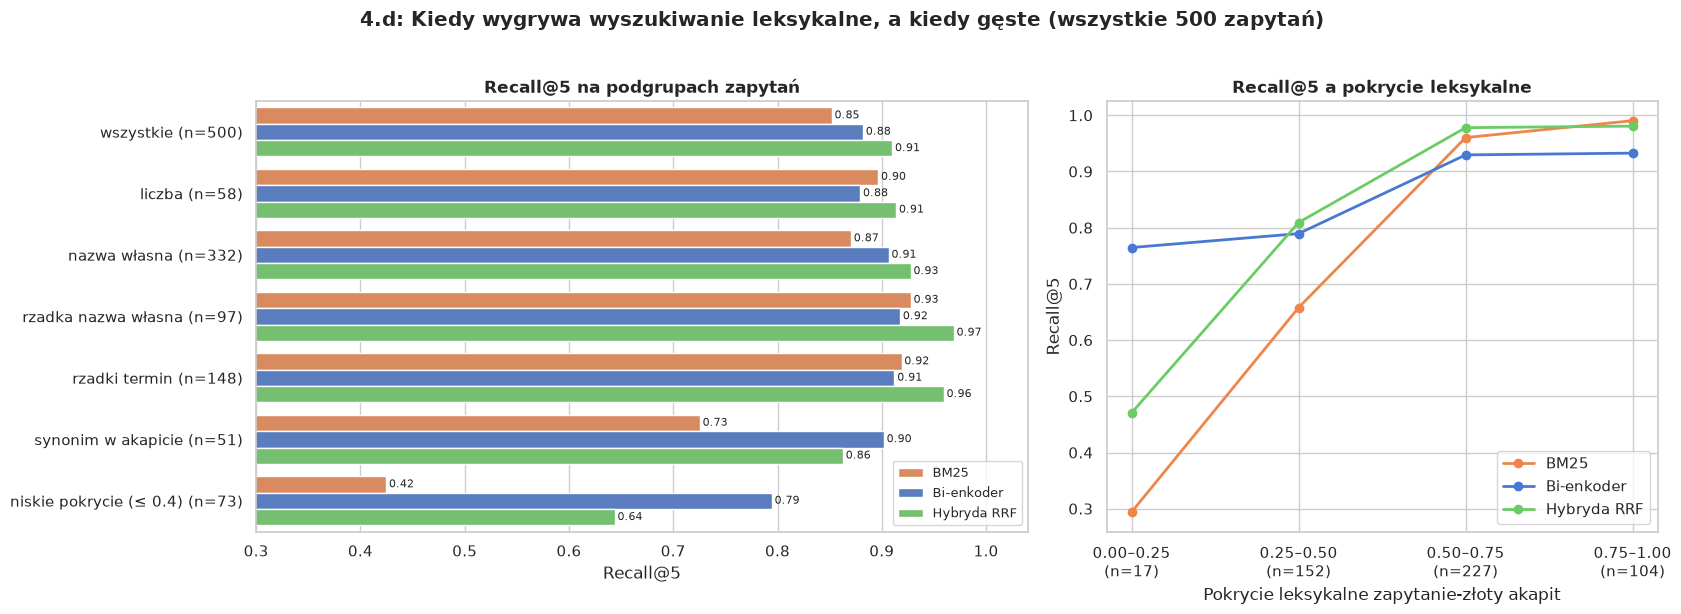

System,BM25,Bi-enkoder,Hybryda RRF
podgrupa,,,
wszystkie (n=500),0.852,0.882,0.910
liczba (n=58),0.897,0.879,0.914
nazwa własna (n=332),0.870,0.907,0.928
rzadka nazwa własna (n=97),0.928,0.918,0.969
rzadki termin (n=148),0.919,0.912,0.959
synonim w akapicie (n=51),0.725,0.902,0.863
niskie pokrycie (≤ 0.4) (n=73),0.425,0.795,0.644


In [11]:
import nltk
from nltk.corpus import wordnet as wn

nltk.download("wordnet", quiet=True)

raw_tok = lambda texts: bm25s.tokenize(texts, stopwords="en", return_ids=False, show_progress=False)


def wordnet_synonym_stems(word):
    # Stemy synonimów słowa (rzeczowniki/przymiotniki/przysłówki, 3 najczęstsze znaczenia).
    if df_counts.get(stemmer.stemWord(word), 0) > 1500:
        return set()
    synsets = [s for s in wn.synsets(word) if s.pos() in ("n", "a", "s", "r")][:3]
    return {stemmer.stemWord(l.name().lower()) for s in synsets for l in s.lemmas()
            if "_" not in l.name() and l.name().lower() != word}


synonym_pairs = {}
subgroups = defaultdict(list)
for q, words in zip(queries, raw_tok([q["text"] for q in queries])):
    q_id, text = q["query_id"], q["text"]
    gold_terms = doc_tokset[qrels[q_id][0]]
    terms = {stemmer.stemWord(w) for w in words}
    caps = [w for w in re.findall(r"[A-Za-z][\w'-]*", text)[1:] if w[0].isupper()]
    coverage = len(terms & gold_terms) / len(terms) if terms else 0.0

    subgroups["wszystkie"].append(q_id)
    if re.search(r"\d", text):
        subgroups["liczba"].append(q_id)
    if caps:
        subgroups["nazwa własna"].append(q_id)
    if any(df_counts.get(stemmer.stemWord(w.lower()), 0) <= 10 for w in caps):
        subgroups["rzadka nazwa własna"].append(q_id)
    if any(df_counts.get(t, 0) <= 10 for t in terms):
        subgroups["rzadki termin"].append(q_id)
    pairs = [(w, sorted(wordnet_synonym_stems(w) & gold_terms)) for w in words if stemmer.stemWord(w) not in gold_terms]
    pairs = [(w, s) for w, s in pairs if s]
    if pairs:
        subgroups["synonim w akapicie"].append(q_id)
        synonym_pairs[q_id] = pairs
    if coverage <= 0.4:
        subgroups["niskie pokrycie (≤ 0.4)"].append(q_id)

GROUP_ORDER = ["wszystkie", "liczba", "nazwa własna", "rzadka nazwa własna", "rzadki termin",
               "synonim w akapicie", "niskie pokrycie (≤ 0.4)"]
sub_rows = []
for g in GROUP_ORDER:
    sub_qrels = {q: qrels[q] for q in subgroups[g]}
    for name in ["BM25", "Bi-enkoder", "Hybryda RRF"]:
        m = evaluate_rankings(SYS3[name], sub_qrels, k=TOP_K)
        sub_rows.append({"podgrupa": f"{g} (n={len(sub_qrels)})", "System": name, **m})
df_sub = pd.DataFrame(sub_rows)

# Recall@5 w funkcji pokrycia leksykalnego (przedziały).
cov_bins = pd.cut(df_feat["pokrycie leksykalne"], bins=[0, 0.25, 0.5, 0.75, 1.0], include_lowest=True)
cov_rows = []
for interval, ids in df_feat.groupby(cov_bins, observed=True)["query_id"]:
    sub_qrels = {q: qrels[q] for q in ids}
    label = f"{max(interval.left, 0):.2f}–{interval.right:.2f}\n(n={len(ids)})"
    for name in ["BM25", "Bi-enkoder", "Hybryda RRF"]:
        cov_rows.append({"pokrycie": label, "System": name, **evaluate_rankings(SYS3[name], sub_qrels, k=TOP_K)})
df_cov = pd.DataFrame(cov_rows)

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.4, 1]})
sns.barplot(data=df_sub, y="podgrupa", x=METRICS[0], hue="System", palette=COLORS, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", fontsize=8, padding=2)
axes[0].set_xlim(0.3, 1.04)
axes[0].set_ylabel("")
axes[0].set_title("Recall@5 na podgrupach zapytań", fontweight="bold")
axes[0].legend(loc="lower right", fontsize=9)

for name in ["BM25", "Bi-enkoder", "Hybryda RRF"]:
    sub = df_cov[df_cov["System"] == name]
    axes[1].plot(sub["pokrycie"], sub[METRICS[0]], marker="o", lw=2, color=COLORS[name], label=name)
axes[1].set_xlabel("Pokrycie leksykalne zapytanie-złoty akapit")
axes[1].set_ylabel(METRICS[0])
axes[1].set_title("Recall@5 a pokrycie leksykalne", fontweight="bold")
axes[1].legend(loc="lower right")
fig.suptitle("4.d: Kiedy wygrywa wyszukiwanie leksykalne, a kiedy gęste (wszystkie 500 zapytań)", fontweight="bold", y=1.02)
fig.tight_layout()
save_fig(fig, "4d_podgrupy")
plt.show()

display(df_sub.pivot(index="podgrupa", columns="System", values=METRICS[0])
        .reindex([r for r in dict.fromkeys(df_sub["podgrupa"])])[["BM25", "Bi-enkoder", "Hybryda RRF"]].round(3))

**Wnioski z podgrup (wszystkie 500 zapytań).**
- **Synonimy (n = 51): wyraźna przewaga bi-enkodera.** Recall@5 0.902 vs 0.725 (o 9 zapytań więcej). Kiedy akapit używa synonimu słowa z zapytania, BM25 traci dopasowanie.
- **Niskie pokrycie / parafraza (n = 73): największa przewaga bi-enkodera.** 0.795 vs 0.425. Tu też widać **słabość RRF**: hybryda (0.644) jest wyraźnie gorsza od samego bi-enkodera. RRF daje obu systemom równy głos, więc gdy BM25 zwraca złe akapity z wysokich pozycji, wypychają one z top-5 trafienia bi-enkodera.
- **Rzadkie terminy (n = 148) i rzadkie nazwy własne (n = 97): praktycznie remis** (0.919 vs 0.912; 0.928 vs 0.918, czyli po 1 zapytaniu różnicy). Ważniejsze, kto na tym zyskuje względem swojej średniej: BM25 rośnie z 0.852 do ~0.92 (+0.07), bi-enkoder z 0.882 do ~0.915 (+0.03). Rzadki termin pomaga więc głównie BM25, a hybryda osiąga tu najlepsze wyniki w całym zbiorze (0.959 / 0.969), bo oba systemy wzajemnie uzupełniają swoje błędy.
- **Liczby (n = 58): kierunek zgodny z hipotezą, ale bez rozstrzygnięcia.** 0.897 vs 0.879 to różnica jednego zapytania.
- **Nazwy własne ogółem (n = 332): wygrywa bi-enkoder** (0.907 vs 0.870), wbrew intuicji. Większość nazw w SQuAD to znane encje (kraje, miasta, postacie historyczne), które model gęsty dobrze reprezentuje. BM25 zyskuje dopiero wtedy, gdy nazwa jest rzadka.

**Pokrycie leksykalne (prawy wykres)** dobrze tłumaczy cały podział. Poniżej ~0.5 wygrywa bi-enkoder, powyżej BM25 (0.96 vs 0.93 i 0.99 vs 0.93). Hybryda trzyma się lepszego z systemów we wszystkich przedziałach poza najniższym (n = 17), gdzie BM25 ją ściąga w dół. Uwaga: pokrycie liczę względem złotego akapitu, więc to narzędzie analizy, a nie cecha znana w momencie wyszukiwania.

### Przykłady: liczby i synonimy

Zapytania z liczbą, w których BM25 stawia złoty akapit wyżej niż bi-enkoder, oraz zapytania z synonimem, w których jest odwrotnie (z wykrytą parą słowo z zapytania → stem synonimu w akapicie).

In [12]:
def rank_or_inf(r):
    return r if r is not None else float("inf")


digit_bm25_better = sorted(
    [q for q in subgroups["liczba"] if rank_or_inf(rank_bm25[q]) < rank_or_inf(rank_dense[q])],
    key=lambda q: rank_bm25[q] - min(rank_or_inf(rank_dense[q]), DEPTH + 1),
)
print(f"Zapytania z liczbą: BM25 wyżej w {len(digit_bm25_better)}, bi-enkoder wyżej w "
      f"{sum(rank_or_inf(rank_dense[q]) < rank_or_inf(rank_bm25[q]) for q in subgroups['liczba'])} "
      f"(z {len(subgroups['liczba'])})\n")
print("#" * 40, "LICZBY: BM25 wyżej", "#" * 40)
for q_id in digit_bm25_better[:4]:
    print(f"[{q_id}] {query_text[q_id]}")
    print(f"  rank BM25: {fmt_rank(rank_bm25[q_id])} | rank bi-enkoder: {fmt_rank(rank_dense[q_id])}")
    print(f"  ZŁOTY: {doc_text[qrels[q_id][0]][:220]}...\n")

syn_dense_better = sorted(
    [q for q in subgroups["synonim w akapicie"] if rank_or_inf(rank_dense[q]) < rank_or_inf(rank_bm25[q])],
    key=lambda q: rank_dense[q] - min(rank_or_inf(rank_bm25[q]), DEPTH + 1),
)
print(f"Zapytania z synonimem: bi-enkoder wyżej w {len(syn_dense_better)}, BM25 wyżej w "
      f"{sum(rank_or_inf(rank_bm25[q]) < rank_or_inf(rank_dense[q]) for q in subgroups['synonim w akapicie'])} "
      f"(z {len(subgroups['synonim w akapicie'])})\n")
print("#" * 40, "SYNONIMY: bi-enkoder wyżej", "#" * 40)
for q_id in syn_dense_better[:6]:
    pairs = ", ".join(f"{w} → {'/'.join(s)}" for w, s in synonym_pairs[q_id])
    print(f"[{q_id}] {query_text[q_id]}")
    print(f"  synonimy: {pairs} | rank BM25: {fmt_rank(rank_bm25[q_id])} | rank bi-enkoder: {fmt_rank(rank_dense[q_id])}")
    print(f"  ZŁOTY: {doc_text[qrels[q_id][0]][:220]}...\n")

Zapytania z liczbą: BM25 wyżej w 11, bi-enkoder wyżej w 9 (z 58)

######################################## LICZBY: BM25 wyżej ########################################
[q_5229] What percent of the population is under 30 years old?
  rank BM25: 13 | rank bi-enkoder: 27
  ZŁOTY: Tajikistan has a population of 7,349,145 (July 2009 est.) of which 70% are under the age of 30 and 35% are between the ages of 14 and 30. Tajiks who speak Tajik (a dialect of Persian) are the main ethnic group, although ...

[q_73579] Who was assassinated on September 22, 189 AD?
  rank BM25: 1 | rank bi-enkoder: 12
  ZŁOTY: General-in-Chief He Jin (d. 189 AD), half-brother to Empress He (d. 189 AD), plotted with Yuan Shao (d. 202 AD) to overthrow the eunuchs by having several generals march to the outskirts of the capital. There, in a writt...

[q_27460] Who was the Duke of Bavaria in 1516?
  rank BM25: 1 | rank bi-enkoder: 8
  ZŁOTY: In 1516, William IV, Duke of Bavaria, adopted the Reinheitsgebot (purity law), 

**Liczby.** W najwyraźniejszych przykładach decyduje dokładne dopasowanie tokenu liczbowego: *„Who was assassinated on September 22, 189 AD?”* (akapit kilka razy powtarza „189 AD”; BM25: 1. miejsce, bi-enkoder: 12.) i *„Who was the Duke of Bavaria in 1516?”* (akapit zaczyna się od „In 1516, William IV, Duke of Bavaria”; BM25: 1., bi-enkoder: 8.). Bi-enkoder rozpoznaje, że pytanie dotyczy daty, ale konkretna wartość liczby to jeden token z kilkunastu i ma mały wpływ na osadzenie całego zdania, więc akapit z inną datą w tym samym temacie może wypaść podobnie. Na całej podgrupie efekt jest jednak mały: BM25 stawia złoty akapit wyżej w 11 zapytaniach z liczbą, bi-enkoder w 9, a w pozostałych 38 pozycja jest taka sama (albo obu systemom brakuje złotego akapitu w top-100). Liczba w pytaniu często jest kontekstem, a nie kluczem do akapitu.

**Synonimy.** Wykryte pary to klasyczne synonimy i warianty nazw: *divide → watershed*, *commonly → usually*, *natives → indigenous*, *person → individual*, *risk → danger*, *Burma → Myanmar*. W każdym z tych przykładów BM25 stawia złoty akapit na pozycjach 38–100 lub dalej, a bi-enkoder na 1–6. Model gęsty był trenowany na parach pytanie–odpowiedź i parafrazach, więc takie słowa mapuje w pobliże siebie, a dla BM25 to po prostu różne tokeny. W całej podgrupie bi-enkoder jest wyżej w 19 z 51 zapytań, a BM25 tylko w 5.

## 4.e Dlaczego RRF używa rang, a nie wartości podobieństwa

Wyniki obu systemów nie są porównywalne, więc nie da się ich po prostu dodać:

1. **Różne skale i znaczenie.** BM25 to suma wag IDF·TF po termach zapytania: jest nieograniczony z góry i rośnie z liczbą i rzadkością termów, więc dłuższe zapytanie z rzadkimi słowami dostaje wyższe wartości. Wynik bi-enkodera to iloczyn skalarny nienormalizowanych osadzeń (`multi-qa-mpnet-base-dot-v1`), z zakresem wyznaczonym przez trening modelu, a nie przez treść zapytania.
2. **Różne rozkłady w obrębie jednego zapytania.** W BM25 często jest jeden wyraźny lider i szybki spadek, w bi-enkoderze wyniki top-100 leżą gęsto. Ta sama różnica wyników znaczy w obu systemach coś innego.
3. **Brak kalibracji.** Żaden z wyników nie jest prawdopodobieństwem trafności, więc nawet po normalizacji min-max „0.8” w BM25 i „0.8” w bi-enkoderze nie oznaczają tego samego. Do tego min-max jest wrażliwy na skrajne wartości w danej liście.
4. **Rangi są od tego niezależne.** Pozycja na liście ma tę samą skalę w każdym systemie, nie wymaga normalizacji ani strojenia wag, a stała `k = 60` tłumi wpływ pojedynczego systemu: różnica między 1. a 2. miejscem (1/61 vs 1/62) jest mała, więc dokument wysoko na **obu** listach wygrywa z dokumentem bardzo wysoko tylko na jednej. Cormack i in. (2009) pokazali, że ta prosta reguła wygrywa z metodami łączącymi wyniki (CombSUM, CombMNZ) i z metodami uczonymi.

Poniżej dowód empiryczny: rozkłady wyników obu systemów oraz porównanie RRF z sumowaniem surowych wyników (CombSUM) i wyników po normalizacji min-max w obrębie zapytania.

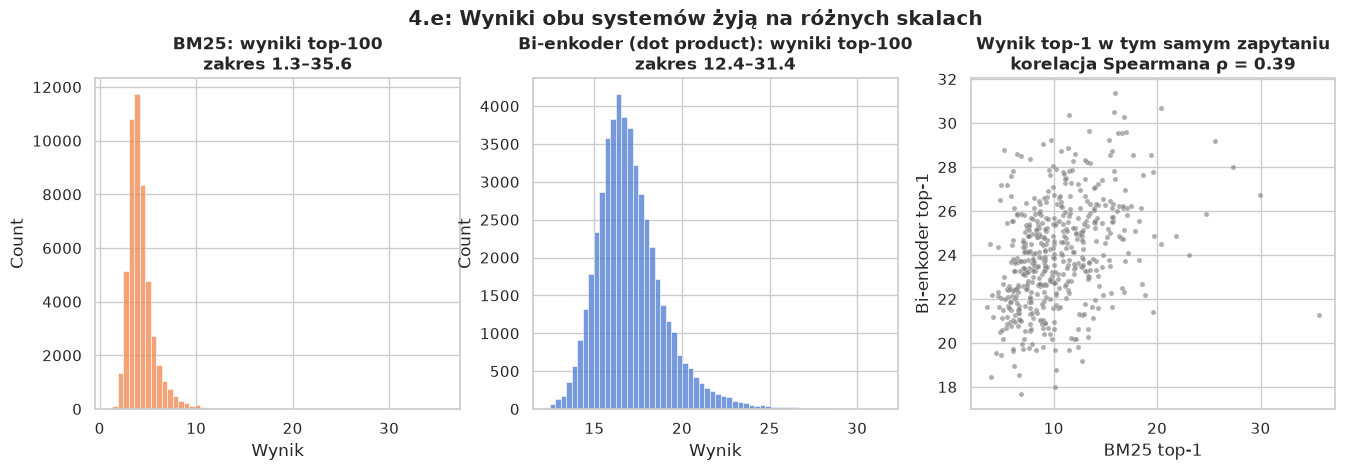

In [13]:
bm25_scores = np.concatenate([[s for _, s in v] for v in bm25_100.values() if v])
dense_scores = np.concatenate([[s for _, s in v] for v in dense_100.values()])
top1 = pd.DataFrame({
    "BM25 top-1": [bm25_100[q][0][1] if bm25_100[q] else np.nan for q in qrels],
    "Bi-enkoder top-1": [dense_100[q][0][1] for q in qrels],
})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.histplot(bm25_scores, bins=60, color=COLORS["BM25"], ax=axes[0])
axes[0].set_title(f"BM25: wyniki top-{DEPTH}\nzakres {bm25_scores.min():.1f}–{bm25_scores.max():.1f}", fontweight="bold")
sns.histplot(dense_scores, bins=60, color=COLORS["Bi-enkoder"], ax=axes[1])
axes[1].set_title(f"Bi-enkoder (dot product): wyniki top-{DEPTH}\nzakres {dense_scores.min():.1f}–{dense_scores.max():.1f}", fontweight="bold")
sns.scatterplot(data=top1, x="BM25 top-1", y="Bi-enkoder top-1", s=14, alpha=0.6, color=MUTED[7], ax=axes[2])
rho = top1.corr(method="spearman").iloc[0, 1]
axes[2].set_title(f"Wynik top-1 w tym samym zapytaniu\nkorelacja Spearmana ρ = {rho:.2f}", fontweight="bold")
for ax in axes[:2]:
    ax.set_xlabel("Wynik")
fig.suptitle("4.e: Wyniki obu systemów żyją na różnych skalach", fontweight="bold", y=1.04)
save_fig(fig, "4e_rozklady_wynikow")
plt.show()

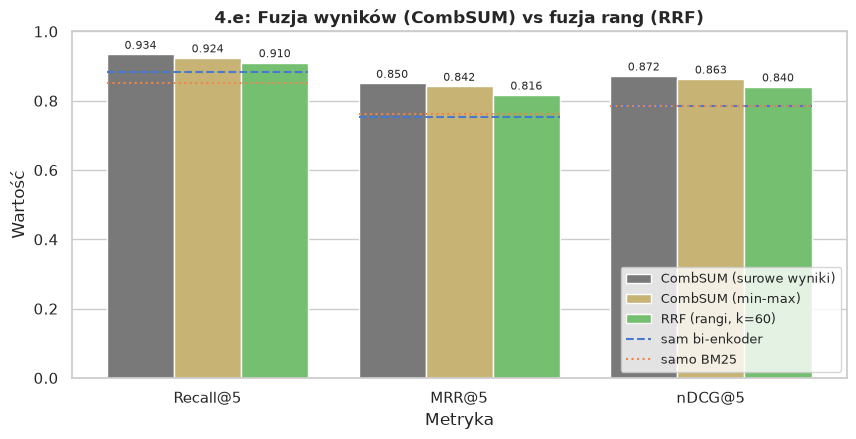

,Recall@5,MRR@5,nDCG@5,top-1 = top-1 BM25,top-1 = top-1 bi-enkodera
Fuzja,,,,,
CombSUM (surowe wyniki),0.934,0.8504,0.8716,0.742,0.750
CombSUM (min-max),0.924,0.8419,0.8628,0.778,0.710
"RRF (rangi, k=60)",0.910,0.8165,0.8400,0.740,0.716


In [14]:
def combsum(rankings_list, normalize, weights=None):
    # CombSUM: suma (ważonych) wyników; dokument nieobecny na liście dostaje od tego systemu 0.
    weights = weights or [1.0] * len(rankings_list)
    fused = {}
    for q_id in qrels:
        scores = defaultdict(float)
        for rankings, w in zip(rankings_list, weights):
            ranked = rankings.get(q_id, [])
            if not ranked:
                continue
            vals = np.array([s for _, s in ranked], dtype=float)
            if normalize:
                lo, hi = vals.min(), vals.max()
                vals = (vals - lo) / (hi - lo) if hi > lo else np.ones_like(vals)
            for (doc_id, _), v in zip(ranked, vals):
                scores[doc_id] += w * float(v)
        fused[q_id] = sorted(scores.items(), key=lambda item: -item[1])
    return fused


FUSIONS = {
    "CombSUM (surowe wyniki)": combsum([bm25_100, dense_100], normalize=False),
    "CombSUM (min-max)": combsum([bm25_100, dense_100], normalize=True),
    "RRF (rangi, k=60)": hybrid_full,
}
df_fusion = pd.DataFrame([{"Fuzja": n, **evaluate_rankings(r, qrels, k=TOP_K)} for n, r in FUSIONS.items()])


def top1_agreement(fused, ref):
    return np.mean([bool(fused[q]) and bool(ref[q]) and fused[q][0][0] == ref[q][0][0] for q in qrels])


df_fusion["top-1 = top-1 BM25"] = [top1_agreement(r, bm25_100) for r in FUSIONS.values()]
df_fusion["top-1 = top-1 bi-enkodera"] = [top1_agreement(r, dense_100) for r in FUSIONS.values()]

fig, ax = plt.subplots(figsize=(10, 4.5))
long = df_fusion.melt(id_vars="Fuzja", value_vars=METRICS, var_name="Metryka", value_name="Wartość")
fusion_colors = {"CombSUM (surowe wyniki)": MUTED[7], "CombSUM (min-max)": MUTED[8], "RRF (rangi, k=60)": COLORS["Hybryda RRF"]}
sns.barplot(data=long, x="Metryka", y="Wartość", hue="Fuzja", palette=fusion_colors, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
for metric_idx, metric in enumerate(METRICS):
    ax.hlines(m_dense[metric], metric_idx - 0.4, metric_idx + 0.4, colors=COLORS["Bi-enkoder"], linestyles="--", lw=1.5,
              label="sam bi-enkoder" if metric_idx == 0 else None)
    ax.hlines(m_bm25[metric], metric_idx - 0.4, metric_idx + 0.4, colors=COLORS["BM25"], linestyles=":", lw=1.5,
              label="samo BM25" if metric_idx == 0 else None)
ax.set_ylim(0, 1)
ax.legend(loc="lower right", fontsize=9)
ax.set_title("4.e: Fuzja wyników (CombSUM) vs fuzja rang (RRF)", fontweight="bold")
save_fig(fig, "4e_ablacja_fuzji")
plt.show()
display(df_fusion.set_index("Fuzja").round(4))

### Czy przewaga CombSUM jest trwała? Test zmiany skali

Surowe wyniki dodają się „poprawnie” tylko wtedy, gdy skale obu systemów przypadkiem do siebie pasują. Sprawdzam to, mnożąc wyniki BM25 przez α (`α·BM25 + bi-enkoder`). Takie przeskalowanie nie zmienia **żadnego** z pojedynczych rankingów, a odpowiada np. innemu wariantowi IDF w BM25, innym `k1`/`b` albo podmianie modelu gęstego na taki, który zwraca kosinus w [-1, 1]. RRF zależy tylko od kolejności, więc jest na to niewrażliwy z definicji, podobnie jak min-max przy samym mnożeniu.

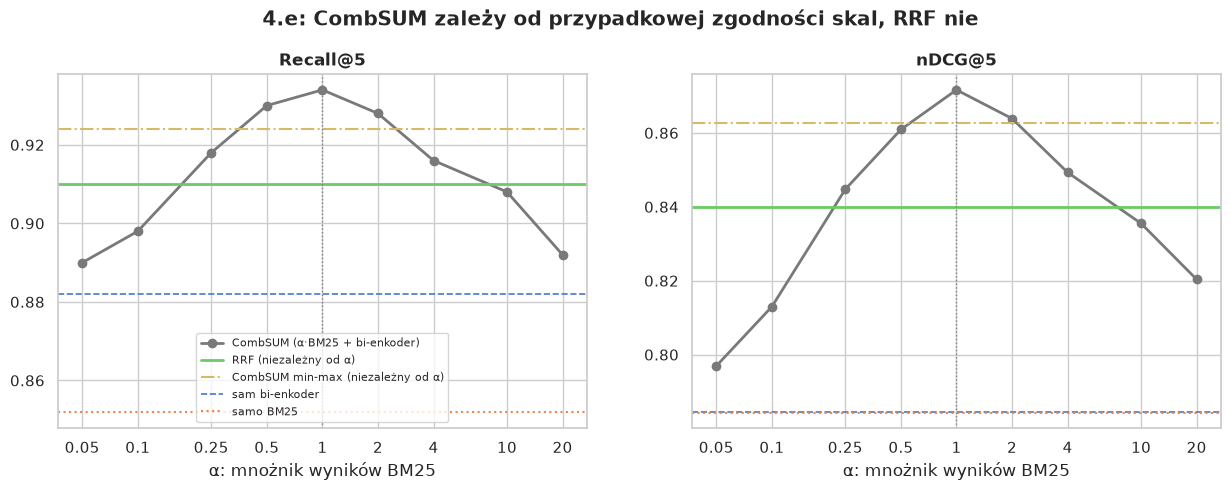

,Recall@5,MRR@5,nDCG@5
α,,,
0.05,0.890,0.7655,0.7969
0.10,0.898,0.7841,0.8130
0.25,0.918,0.8198,0.8448
0.50,0.930,0.8375,0.8609
1.00,0.934,0.8504,0.8716
2.00,0.928,0.8421,0.8639
4.00,0.916,0.8270,0.8493
10.00,0.908,0.8114,0.8355
20.00,0.892,0.7963,0.8203


In [15]:
ALPHAS = [0.05, 0.1, 0.25, 0.5, 1, 2, 4, 10, 20]
alpha_rows = []
for a in ALPHAS:
    fused = combsum([bm25_100, dense_100], normalize=False, weights=[a, 1.0])
    alpha_rows.append({"α": a, **evaluate_rankings(fused, qrels, k=TOP_K)})
df_alpha = pd.DataFrame(alpha_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharex=True)
for ax, metric in zip(axes, [METRICS[0], METRICS[2]]):
    ax.plot(df_alpha["α"], df_alpha[metric], marker="o", color=MUTED[7], lw=2, label="CombSUM (α·BM25 + bi-enkoder)")
    ax.axhline(evaluate_rankings(hybrid_full, qrels, k=TOP_K)[metric], color=COLORS["Hybryda RRF"], lw=2, label="RRF (niezależny od α)")
    ax.axhline(df_fusion.set_index("Fuzja").loc["CombSUM (min-max)", metric], color=MUTED[8], lw=1.5, ls="-.", label="CombSUM min-max (niezależny od α)")
    ax.axhline(m_dense[metric], color=COLORS["Bi-enkoder"], ls="--", lw=1.2, label="sam bi-enkoder")
    ax.axhline(m_bm25[metric], color=COLORS["BM25"], ls=":", lw=1.5, label="samo BM25")
    ax.axvline(1, color="gray", lw=1, ls=":")
    ax.set_xscale("log")
    ax.set_xticks(ALPHAS, labels=[str(a) for a in ALPHAS])
    ax.set_xlabel("α: mnożnik wyników BM25")
    ax.set_title(metric, fontweight="bold")
axes[0].legend(fontsize=8, loc="lower center")
fig.suptitle("4.e: CombSUM zależy od przypadkowej zgodności skal, RRF nie", fontweight="bold", y=1.02)
save_fig(fig, "4e_skala_combsum")
plt.show()
display(df_alpha.set_index("α").round(4))

**Wnioski (4.e).** Wynik jest ciekawszy, niż zakłada pytanie: na tym zbiorze **CombSUM na surowych wynikach wygrywa z RRF** (Recall@5 0.934 vs 0.910, nDCG@5 0.872 vs 0.840), a CombSUM po min-max też jest lepszy (0.924 / 0.863). Fuzja wyników wykorzystuje informację, którą RRF wyrzuca: **pewność** systemu. Gdy BM25 ma lidera z dużą przewagą, CombSUM to widzi, a RRF widzi tylko „1. miejsce”, tak samo przy przewadze ogromnej i minimalnej.

Test skali pokazuje, że ta przewaga ma swoją cenę:
- Najlepszy wynik CombSUM wypada **dokładnie przy α = 1**, czyli przy przypadkowej zgodności skal. W obrębie zapytania rozpiętość wyników BM25 i iloczynu skalarnego `multi-qa-mpnet-base-dot-v1` jest tu podobnego rzędu.
- CombSUM jest lepszy od RRF w szerokim, ale ograniczonym zakresie α ≈ 0.25–4. Przy rozjeździe skal o rząd wielkości lub więcej spada poniżej RRF (α = 10: Recall@5 0.908; α = 20: 0.892), a przy α = 0.05 nDCG@5 (0.797) jest niewiele lepsze od samego bi-enkodera, bo BM25 przestaje się liczyć. Taki rozjazd zdarza się w praktyce: model gęsty zwracający kosinus z przedziału [-1, 1] zamiast iloczynu skalarnego rzędu 12–31 odpowiada α rzędu kilkudziesięciu.
- Dobranie α (albo wag dla min-max) to strojenie, które trzeba robić na osobnym zbiorze walidacyjnym i powtarzać po każdej zmianie modelu, tokenizacji czy parametrów BM25. Tutaj α = 1 „wybrało się samo” i oceniamy je na zbiorze testowym, więc przewaga CombSUM jest optymistyczna.

**Dlaczego więc rangi.** RRF nie zmienia się przy żadnej monotonicznej transformacji wyników któregokolwiek systemu (skalowanie, przesunięcie, logarytm, podmiana modelu na inny o tej samej kolejności). Nie wymaga normalizacji, kalibracji ani zbioru do strojenia i nie pozwala jednemu systemowi zdominować drugiego. Płacimy za to utratą informacji o pewności: tutaj ~2.4 pp Recall@5 względem sumy z akurat pasującą skalą. To zwykle dobra cena za odporność, dlatego RRF z k = 60 jest gotową, domyślną metodą fuzji hybrydowej np. w Elasticsearch i OpenSearch.

## 5.a-b Re-ranking cross-enkoderem

Do potoku hybrydowego dokładam `rerank` z `utils/rerank.py`: cross-enkoder `cross-encoder/ms-marco-MiniLM-L6-v2` ocenia pary (zapytanie, akapit) dla **top-50 kandydatów hybrydy RRF** na **wszystkich 500 zapytaniach** i zwraca nowy ranking. Uzasadnienie wyboru puli: [rerank_pool.md](rerank_pool.md).

Warianty:
- **Hybryda + CE (top-50)**: wariant główny.
- **Hybryda + CE (top-5)**: wariant kontrolny. Cross-enkoder tylko przestawia 5 dokumentów, które hybryda już zwróciła, więc Recall@5 **musi** zostać bez zmian (sprawdzam assertem).
- **Hybryda + CE L12 (top-50)**: większy model `ms-marco-MiniLM-L12-v2` dla porównania.

Czas re-rankingu dodaję do czasu hybrydy (modele załadowane i rozgrzane przed pomiarem).

In [16]:
warm = {q_id: hybrid_full[q_id][:4] for q_id in list(hybrid_full)[:8]}
for model_name in (CE_MODEL, CE_MODEL_L12):
    get_cross_encoder(model_name)
    rerank(warm, queries, docs, model_name=model_name, top_n=4, top_k=4)

# top_k = 50: pełny przestawiony ranking puli (potrzebny do krzywych Recall@k); metryki @5 i tak patrzą na 5 pierwszych.
ce_50, t = timed(rerank, hybrid_full, queries, docs, model_name=CE_MODEL, top_n=CE_TOP_N, top_k=CE_TOP_N)
LATENCY_MS["Hybryda + CE (top-50)"] = LATENCY_MS["Hybryda RRF"] + t / len(queries) * 1000

ce_5, t = timed(rerank, hybrid_full, queries, docs, model_name=CE_MODEL, top_n=TOP_K, top_k=TOP_K)
LATENCY_MS["Hybryda + CE (top-5)"] = LATENCY_MS["Hybryda RRF"] + t / len(queries) * 1000

ce_l12, t = timed(rerank, hybrid_full, queries, docs, model_name=CE_MODEL_L12, top_n=CE_TOP_N, top_k=CE_TOP_N)
LATENCY_MS["Hybryda + CE L12 (top-50)"] = LATENCY_MS["Hybryda RRF"] + t / len(queries) * 1000

# Wariant kontrolny: ten sam zbiór 5 dokumentów, ta sama Recall@5.
assert all({d for d, _ in ce_5[q]} == {d for d, _ in hybrid_full[q][:TOP_K]} for q in qrels)
assert evaluate_rankings(ce_5, qrels, k=TOP_K)[METRICS[0]] == m_hybrid[METRICS[0]]
print("OK: re-ranking top-5 nie zmienia zbioru dokumentów ani Recall@5")

for name, r in {"Hybryda + CE (top-5)": ce_5, "Hybryda + CE (top-50)": ce_50, "Hybryda + CE L12 (top-50)": ce_l12}.items():
    print(f"{name}:", {k: round(v, 4) for k, v in evaluate_rankings(r, qrels, k=TOP_K).items()}, f"| {LATENCY_MS[name]:.2f} ms/zapytanie")

OK: re-ranking top-5 nie zmienia zbioru dokumentów ani Recall@5
Hybryda + CE (top-5): {'Recall@5': 0.91, 'MRR@5': 0.8585, 'nDCG@5': 0.8715} | 10.82 ms/zapytanie
Hybryda + CE (top-50): {'Recall@5': 0.946, 'MRR@5': 0.8886, 'nDCG@5': 0.9031} | 78.99 ms/zapytanie
Hybryda + CE L12 (top-50): {'Recall@5': 0.96, 'MRR@5': 0.9038, 'nDCG@5': 0.918} | 155.70 ms/zapytanie


### Rozmiar puli re-rankingu

Cross-enkoder ocenia `top_n` kandydatów hybrydy, n ∈ {5, 10, 20, 50, 100}. Linia przerywana to **sufit**: Recall@n hybrydy, czyli odsetek zapytań, dla których złoty dokument w ogóle trafia do puli. Re-ranker nie odzyska dokumentu spoza puli.

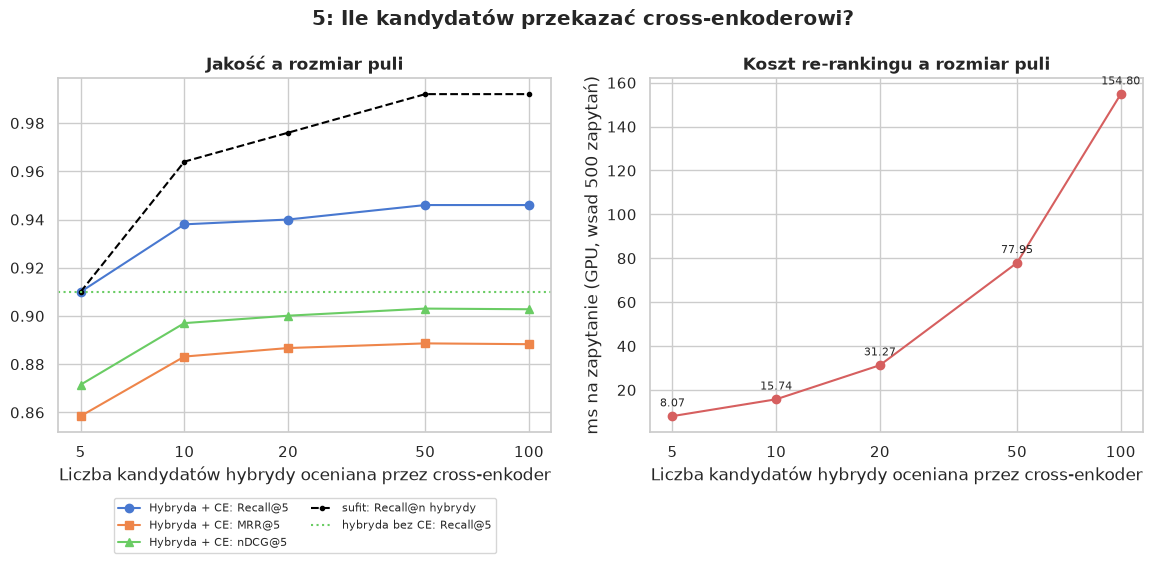

,pula,Recall@5,MRR@5,nDCG@5,sufit (Recall@n hybrydy),ms/zapytanie (CE)
0,5,0.910,0.8585,0.8715,0.910,8.0663
1,10,0.938,0.8832,0.8970,0.964,15.7405
2,20,0.940,0.8867,0.9001,0.976,31.2736
3,50,0.946,0.8886,0.9031,0.992,77.9471
4,100,0.946,0.8883,0.9028,0.992,154.7994


In [17]:
pool_rows = []
for n in [5, 10, 20, 50, 100]:
    reranked, t = timed(rerank, hybrid_full, queries, docs, model_name=CE_MODEL, top_n=n, top_k=TOP_K)
    pool_rows.append({
        "pula": n,
        **evaluate_rankings(reranked, qrels, k=TOP_K),
        "sufit (Recall@n hybrydy)": evaluate_rankings(hybrid_full, qrels, k=n)[f"Recall@{n}"],
        "ms/zapytanie (CE)": t / len(queries) * 1000,
    })
df_pool = pd.DataFrame(pool_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
for metric, marker in zip(METRICS, ["o", "s", "^"]):
    ax.plot(df_pool["pula"], df_pool[metric], marker=marker, label=f"Hybryda + CE: {metric}")
ax.plot(df_pool["pula"], df_pool["sufit (Recall@n hybrydy)"], ls="--", color="black", marker=".", label="sufit: Recall@n hybrydy")
ax.axhline(m_hybrid[METRICS[0]], color=COLORS["Hybryda RRF"], ls=":", lw=1.5, label=f"hybryda bez CE: {METRICS[0]}")
ax.set_xscale("log")
ax.set_xticks(df_pool["pula"], labels=df_pool["pula"].astype(str))
ax.set_xlabel("Liczba kandydatów hybrydy oceniana przez cross-enkoder")
ax.set_title("Jakość a rozmiar puli", fontweight="bold")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)

ax = axes[1]
ax.plot(df_pool["pula"], df_pool["ms/zapytanie (CE)"], marker="o", color=COLORS["Hybryda + CE (top-50)"])
for _, row in df_pool.iterrows():
    ax.annotate(f"{row['ms/zapytanie (CE)']:.2f}", (row["pula"], row["ms/zapytanie (CE)"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_xscale("log")
ax.set_xticks(df_pool["pula"], labels=df_pool["pula"].astype(str))
ax.set_xlabel("Liczba kandydatów hybrydy oceniana przez cross-enkoder")
ax.set_ylabel("ms na zapytanie (GPU, wsad 500 zapytań)")
ax.set_title("Koszt re-rankingu a rozmiar puli", fontweight="bold")
fig.suptitle("5: Ile kandydatów przekazać cross-enkoderowi?", fontweight="bold", y=1.03)
save_fig(fig, "5_pula_rerankingu")
plt.show()
display(df_pool.round(4))

**Wnioski.** Największy zysk daje poszerzenie puli z 5 do 10 (Recall@5 0.910 → 0.938). Od 50 krzywa jest płaska (50 i 100 dają ten sam wynik), a sufit Recall@50 hybrydy wynosi 0.992. Koszt rośnie liniowo, ~1.6 ms na kandydata przy przetwarzaniu wsadowym (dla pojedynczego zapytania więcej, patrz 5.c (6)). Pula 50 to najmniejsza, przy której jakość się nasyca. Przy ograniczonym budżecie czasu pula 10–20 daje 90–95% zysku nDCG@5 za 20–40% kosztu. Szczegóły: [rerank_pool.md](rerank_pool.md).

## 5.c Porównanie wszystkich wariantów

Wykresy są głównym porównaniem, tabela z liczbami jest na końcu sekcji.

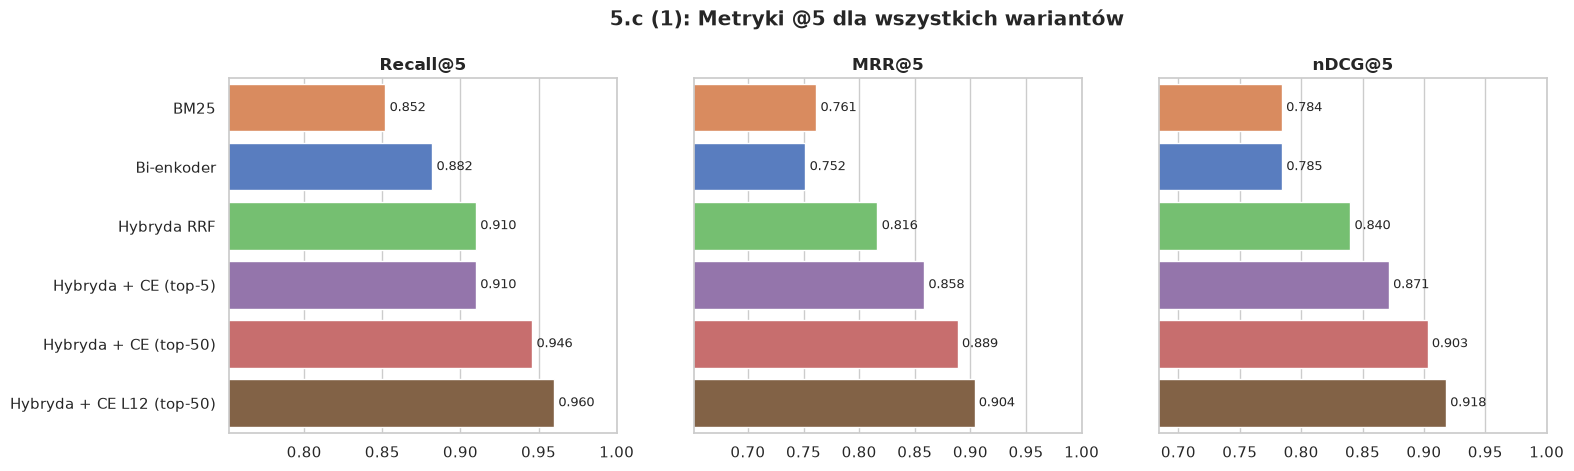

In [18]:
SYSTEMS = {
    "BM25": bm25_100,
    "Bi-enkoder": dense_100,
    "Hybryda RRF": hybrid_full,
    "Hybryda + CE (top-5)": ce_5,
    "Hybryda + CE (top-50)": ce_50,
    "Hybryda + CE L12 (top-50)": ce_l12,
}
df_all = pd.DataFrame([
    {"System": name, **evaluate_rankings(r, qrels, k=TOP_K), "ms/zapytanie": LATENCY_MS[name]}
    for name, r in SYSTEMS.items()
])

# Wykres 1: metryki @5, jeden panel na metrykę.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, metric in zip(axes, METRICS):
    sns.barplot(data=df_all, y="System", x=metric, hue="System", palette=COLORS, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=9, padding=3)
    lo = df_all[metric].min()
    ax.set_xlim(max(0, lo - 0.1), 1.0)
    ax.set_title(metric, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("5.c (1): Metryki @5 dla wszystkich wariantów", fontweight="bold", y=1.03)
save_fig(fig, "5c_1_metryki")
plt.show()

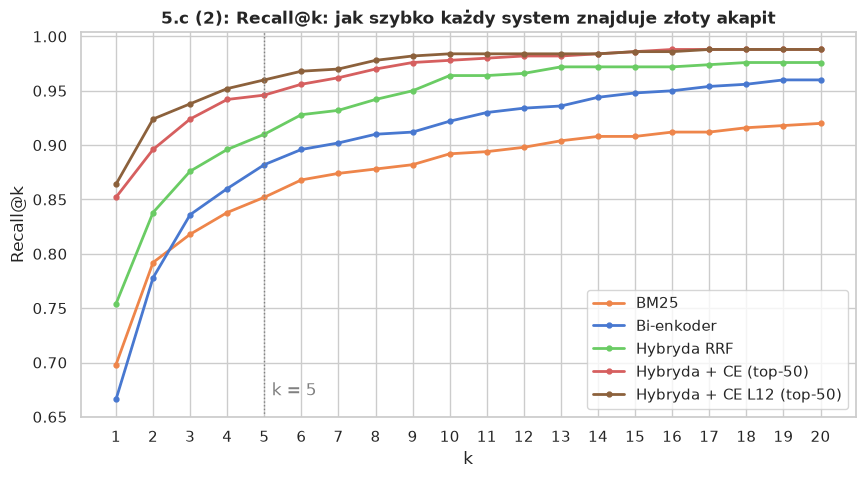

In [19]:
# Wykres 2: krzywe Recall@k (k = 1..20). Wariant CE (top-5) ma tylko 5 pozycji, więc go pomijam.
ks = list(range(1, 21))
fig, ax = plt.subplots(figsize=(10, 5))
for name, r in SYSTEMS.items():
    if name == "Hybryda + CE (top-5)":
        continue
    vals = [evaluate_rankings(r, qrels, k=k)[f"Recall@{k}"] for k in ks]
    ax.plot(ks, vals, marker="o", ms=3.5, color=COLORS[name], label=name, lw=2)
ax.axvline(TOP_K, color="gray", ls=":", lw=1)
ax.text(TOP_K + 0.2, ax.get_ylim()[0] + 0.02, "k = 5", color="gray")
ax.set_xticks(ks)
ax.set_xlabel("k")
ax.set_ylabel("Recall@k")
ax.set_title("5.c (2): Recall@k: jak szybko każdy system znajduje złoty akapit", fontweight="bold")
ax.legend(loc="lower right")
save_fig(fig, "5c_2_recall_at_k")
plt.show()

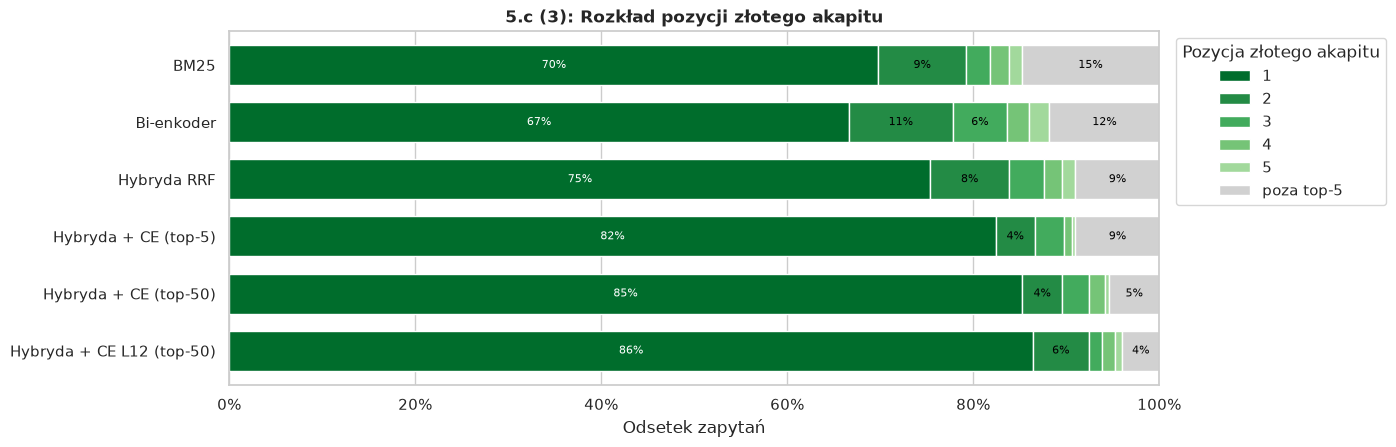

In [20]:
# Wykres 3: na której pozycji jest złoty dokument.
POS_LABELS = ["1", "2", "3", "4", "5", "poza top-5"]
pos_rows = []
for name, r in SYSTEMS.items():
    ranks = gold_ranks(r, qrels)
    c = Counter(str(v) if in_top(v) else "poza top-5" for v in ranks.values())
    pos_rows.append({"System": name, **{p: c.get(p, 0) / len(qrels) for p in POS_LABELS}})
df_pos = pd.DataFrame(pos_rows).set_index("System")

pos_colors = list(sns.color_palette("Greens_r", 7)[:5]) + [(0.82, 0.82, 0.82)]
fig, ax = plt.subplots(figsize=(12, 4.6))
df_pos[POS_LABELS].plot.barh(stacked=True, color=pos_colors, ax=ax, width=0.7, edgecolor="white")
for container, label in zip(ax.containers, POS_LABELS):
    ax.bar_label(container, labels=[f"{w:.0%}" if w >= 0.04 else "" for w in container.datavalues],
                 label_type="center", fontsize=8, color="black" if label != "1" else "white")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlim(0, 1)
ax.set_xlabel("Odsetek zapytań")
ax.set_ylabel("")
ax.legend(title="Pozycja złotego akapitu", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("5.c (3): Rozkład pozycji złotego akapitu", fontweight="bold")
save_fig(fig, "5c_3_pozycje")
plt.show()

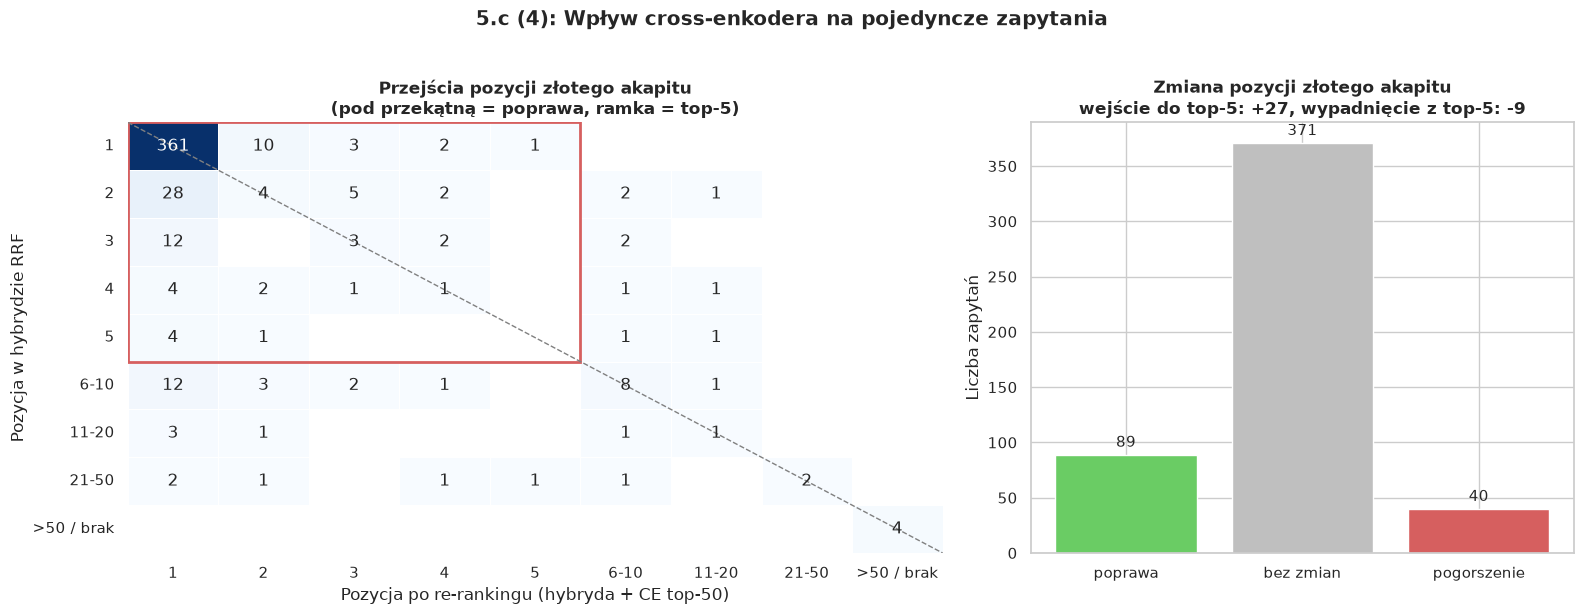

In [21]:
# Wykres 4: jak cross-enkoder przestawia złoty akapit (hybryda RRF -> hybryda + CE top-50).
BINS = ["1", "2", "3", "4", "5", "6-10", "11-20", "21-50", ">50 / brak"]


def rank_bin(r):
    if r is None or r > 50:
        return ">50 / brak"
    if r <= 5:
        return str(r)
    return "6-10" if r <= 10 else "11-20" if r <= 20 else "21-50"


rank_ce = gold_ranks(ce_50, qrels)
trans = pd.crosstab(
    pd.Categorical([rank_bin(rank_hybrid[q]) for q in qrels], categories=BINS),
    pd.Categorical([rank_bin(rank_ce[q]) for q in qrels], categories=BINS),
    dropna=False,
)
inf = float("inf")
before = {q: rank_hybrid[q] or inf for q in qrels}
after = {q: rank_ce[q] or inf for q in qrels}
moves = {
    "poprawa": sum(after[q] < before[q] for q in qrels),
    "bez zmian": sum(after[q] == before[q] for q in qrels),
    "pogorszenie": sum(after[q] > before[q] for q in qrels),
}
into_top5 = sum(after[q] <= TOP_K < before[q] for q in qrels)
out_of_top5 = sum(before[q] <= TOP_K < after[q] for q in qrels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.5, 1]})
mask = trans.values == 0
sns.heatmap(trans, annot=True, fmt="d", mask=mask, cmap="Blues", cbar=False, linewidths=0.5, linecolor="white", ax=axes[0])
axes[0].grid(False)
axes[0].plot([0, len(BINS)], [0, len(BINS)], color="gray", lw=1, ls="--")
axes[0].add_patch(plt.Rectangle((0, 0), 5, 5, fill=False, edgecolor=COLORS["Hybryda + CE (top-50)"], lw=2))
axes[0].set_xlabel("Pozycja po re-rankingu (hybryda + CE top-50)")
axes[0].set_ylabel("Pozycja w hybrydzie RRF")
axes[0].set_title("Przejścia pozycji złotego akapitu\n(pod przekątną = poprawa, ramka = top-5)", fontweight="bold")

bar_colors = [COLORS["Hybryda RRF"], (0.75, 0.75, 0.75), COLORS["Hybryda + CE (top-50)"]]
bars = axes[1].bar(list(moves), list(moves.values()), color=bar_colors)
axes[1].bar_label(bars, fontsize=11, padding=3)
axes[1].set_ylabel("Liczba zapytań")
axes[1].set_title(f"Zmiana pozycji złotego akapitu\nwejście do top-5: +{into_top5}, wypadnięcie z top-5: -{out_of_top5}", fontweight="bold")
fig.suptitle("5.c (4): Wpływ cross-enkodera na pojedyncze zapytania", fontweight="bold", y=1.02)
fig.tight_layout()
save_fig(fig, "5c_4_wplyw_ce")
plt.show()

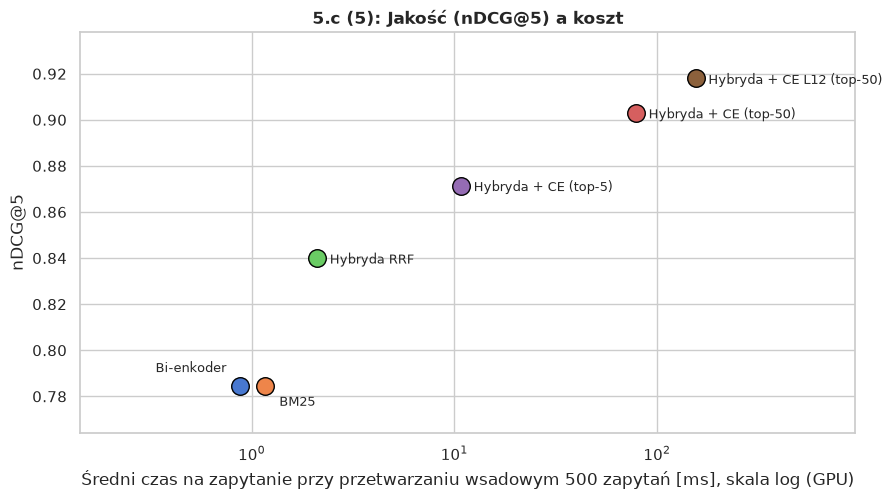

,Recall@5,MRR@5,nDCG@5,ms/zapytanie
System,,,,
BM25,0.852,0.7615,0.7843,1.1701
Bi-enkoder,0.882,0.7517,0.7845,0.8765
Hybryda RRF,0.910,0.8165,0.8400,2.1100
Hybryda + CE (top-5),0.910,0.8585,0.8715,10.8238
Hybryda + CE (top-50),0.946,0.8886,0.9031,78.9948
Hybryda + CE L12 (top-50),0.960,0.9038,0.9180,155.7010


In [22]:
# Wykres 5: jakość a czas.
fig, ax = plt.subplots(figsize=(10, 5.2))
metric = METRICS[2]
# BM25 i bi-enkoder leżą prawie w tym samym punkcie, więc ich etykiety rozsuwam w pionie.
LABEL_OFFSET = {"BM25": (10, -14), "Bi-enkoder": (-10, 10)}
for _, row in df_all.iterrows():
    ax.scatter(row["ms/zapytanie"], row[metric], s=160, color=COLORS[row["System"]], edgecolor="black", zorder=3)
    dx, dy = LABEL_OFFSET.get(row["System"], (9, -4))
    ax.annotate(row["System"], (row["ms/zapytanie"], row[metric]), textcoords="offset points", xytext=(dx, dy),
                ha="right" if dx < 0 else "left", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Średni czas na zapytanie przy przetwarzaniu wsadowym 500 zapytań [ms], skala log (GPU)")
ax.set_ylabel(metric)
ax.set_title(f"5.c (5): Jakość ({metric}) a koszt", fontweight="bold")
ax.margins(x=0.35, y=0.15)
save_fig(fig, "5c_5_jakosc_czas")
plt.show()

display(df_all.set_index("System").round(4))

### Przepustowość a opóźnienie pojedynczego zapytania

Kolumna `ms/zapytanie` powyżej to **przepustowość**: czas obsługi wszystkich 500 zapytań naraz (jeden wsad na GPU) podzielony przez 500. Wsad rozkłada stałe koszty (uruchomienie kerneli GPU, przygotowanie tensora) na wiele zapytań. W wyszukiwarce działającej na żywo zapytania przychodzą pojedynczo, więc liczy się **opóźnienie**: czas od przyjścia jednego zapytania do odpowiedzi. Mierzę je osobno dla 100 zapytań obsługiwanych po kolei, każdy etap potoku osobno (BM25 i bi-enkoder liczone sekwencyjnie, bez zrównoleglania).

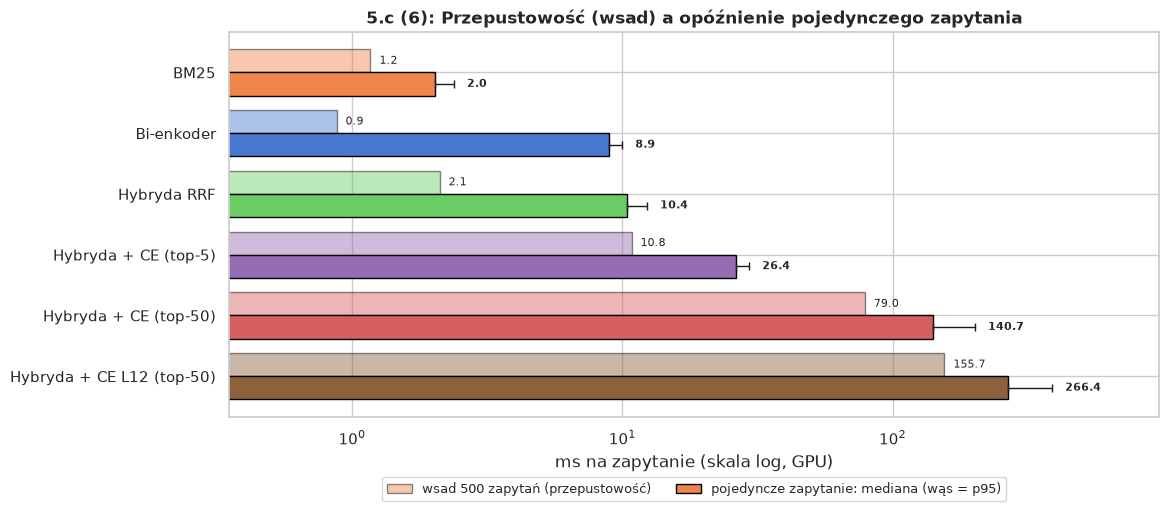

,wsad: ms/zapytanie,pojedyncze: mediana [ms],pojedyncze: p95 [ms],mediana / wsad
System,,,,
BM25,1.17,2.03,2.38,1.74
Bi-enkoder,0.88,8.91,9.98,10.16
Hybryda RRF,2.11,10.44,12.33,4.95
Hybryda + CE (top-5),10.82,26.40,29.43,2.44
Hybryda + CE (top-50),78.99,140.72,201.53,1.78
Hybryda + CE L12 (top-50),155.70,266.38,388.73,1.71


In [23]:
LAT_N = 100
stage_ms = defaultdict(list)


def pipeline_once(q):
    qs = [q]
    t0 = time.perf_counter()
    b = search_bm25(bm25, qs, docs, top_k=DEPTH)
    t1 = time.perf_counter()
    e = bi_model.encode([q["text"]], convert_to_numpy=True, show_progress_bar=False)
    d = search_faiss(index, e, qs, docs, top_k=DEPTH)
    t2 = time.perf_counter()
    f = reciprocal_rank_fusion([b, d], k=RRF_K)
    t3 = time.perf_counter()
    rerank(f, qs, docs, model_name=CE_MODEL, top_n=TOP_K, top_k=TOP_K)
    t4 = time.perf_counter()
    rerank(f, qs, docs, model_name=CE_MODEL, top_n=CE_TOP_N, top_k=TOP_K)
    t5 = time.perf_counter()
    rerank(f, qs, docs, model_name=CE_MODEL_L12, top_n=CE_TOP_N, top_k=TOP_K)
    t6 = time.perf_counter()
    return {"bm25": t1 - t0, "dense": t2 - t1, "fuse": t3 - t2, "ce5": t4 - t3, "ce50": t5 - t4, "l12": t6 - t5}


for q in queries[:5]:  # rozgrzewka
    pipeline_once(q)
for q in queries[:LAT_N]:
    s = {k: v * 1000 for k, v in pipeline_once(q).items()}
    hyb = s["bm25"] + s["dense"] + s["fuse"]
    stage_ms["BM25"].append(s["bm25"])
    stage_ms["Bi-enkoder"].append(s["dense"])
    stage_ms["Hybryda RRF"].append(hyb)
    stage_ms["Hybryda + CE (top-5)"].append(hyb + s["ce5"])
    stage_ms["Hybryda + CE (top-50)"].append(hyb + s["ce50"])
    stage_ms["Hybryda + CE L12 (top-50)"].append(hyb + s["l12"])

df_lat = pd.DataFrame([
    {
        "System": name,
        "wsad: ms/zapytanie": LATENCY_MS[name],
        "pojedyncze: mediana [ms]": np.median(v),
        "pojedyncze: p95 [ms]": np.percentile(v, 95),
    }
    for name, v in stage_ms.items()
])
df_lat["mediana / wsad"] = df_lat["pojedyncze: mediana [ms]"] / df_lat["wsad: ms/zapytanie"]

fig, ax = plt.subplots(figsize=(12, 5))
y = np.arange(len(df_lat))
h = 0.38
colors = [COLORS[s] for s in df_lat["System"]]
ax.barh(y - h / 2, df_lat["wsad: ms/zapytanie"], height=h, color=colors, alpha=0.45, edgecolor="black", label="wsad 500 zapytań (przepustowość)")
med = df_lat["pojedyncze: mediana [ms]"]
p95 = df_lat["pojedyncze: p95 [ms]"]
ax.barh(y + h / 2, med, height=h, color=colors, edgecolor="black", xerr=[np.zeros(len(med)), p95 - med],
        error_kw={"capsize": 3, "lw": 1}, label="pojedyncze zapytanie: mediana (wąs = p95)")
for i, (b, m) in enumerate(zip(df_lat["wsad: ms/zapytanie"], med)):
    ax.text(b * 1.08, i - h / 2, f"{b:.1f}", va="center", fontsize=8)
    ax.text(p95.iloc[i] * 1.12, i + h / 2, f"{m:.1f}", va="center", fontsize=8, fontweight="bold")
ax.set_yticks(y, labels=df_lat["System"])
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("ms na zapytanie (skala log, GPU)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
ax.set_title("5.c (6): Przepustowość (wsad) a opóźnienie pojedynczego zapytania", fontweight="bold")
ax.margins(x=0.15)
save_fig(fig, "5c_6_opoznienie")
plt.show()
display(df_lat.set_index("System").round(2))

**Wnioski.** Przepustowość wsadowa zaniża koszt pojedynczego zapytania 1.5–10×:
- **Bi-enkoder: 0.9 → ~9 ms (10×).** Zakodowanie jednego krótkiego zapytania na GPU to prawie sam stały narzut (wywołanie modelu, transfer na kartę), który we wsadzie rozkłada się na 500 zapytań.
- **BM25 na CPU prawie nie zależy od wsadu** (~1.2 → ~2 ms), więc dla pojedynczego zapytania jest najtańszym etapem potoku.
- **Cross-enkoder top-50: mediana ~141 ms, p95 ~200 ms.** W wyszukiwarce działającej na żywo to już odczuwalne opóźnienie. L12 (mediana ~265 ms, p95 ~390 ms) przekracza typowy budżet interaktywnego wyszukiwania.

Kolejność systemów i wnioski o jakości się nie zmieniają, ale wzmacnia się wniosek z [rerank_pool.md](rerank_pool.md): przy obsłudze pojedynczych zapytań na żywo rozsądniejsza jest pula 10–20 kandydatów.

**Wnioski (5.c).**
- **Cross-enkoder daje największy pojedynczy skok jakości w potoku.** Hybryda + CE (top-50) osiąga Recall@5 0.946, MRR@5 0.889 i nDCG@5 0.903. To +0.036 / +0.072 / +0.063 względem hybrydy oraz +0.064 / +0.137 / +0.118 względem samego bi-enkodera z pkt 3. Najbardziej rośnie MRR: złoty akapit jest na 1. miejscu w 85% zapytań (hybryda 75%, bi-enkoder 67%).
- **Dwa źródła zysku.** Wariant top-5 (te same dokumenty, inna kolejność) daje +0.042 MRR@5 przy niezmienionym Recall@5. Szersza pula dokłada odzyskiwanie akapitów spoza top-5: 27 zapytań wchodzi do top-5, 9 z niego wypada.
- **Re-ranking pomaga per saldo, nie w każdym zapytaniu.** Pozycja złotego akapitu poprawia się w 89 zapytaniach, pogarsza w 40, a w 371 się nie zmienia. Na 1. miejsce trafia w 65 zapytaniach, z 1. miejsca spada w 16.
- **Krzywa Recall@k:** przewaga CE jest największa na małych k (Recall@1 0.852 vs 0.754 dla hybrydy) i maleje do ~0.01 przy k = 20, bo re-ranker tylko przestawia pulę hybrydy.
- **Koszt (przepustowość wsadowa):** BM25, bi-enkoder i hybryda kosztują 1–2 ms na zapytanie, CE top-50 ~79 ms (~40× więcej), a L12 ~156 ms za kolejne +0.014 Recall@5 / +0.015 nDCG@5. Hybryda bez CE to bardzo dobry punkt pośredni: +0.055 nDCG@5 względem bi-enkodera za ~1 ms więcej. Opóźnienie pojedynczego zapytania jest wyższe, patrz niżej.

### Przykłady: gdzie cross-enkoder naprawił, a gdzie zepsuł ranking

In [24]:
def show_ce_case(q_id):
    gold = qrels[q_id][0]
    print("=" * 110)
    print(f"[{q_id}] {query_text[q_id]}")
    print(f"  pozycja złotego akapitu: hybryda {fmt_rank(rank_hybrid[q_id])} -> CE {fmt_rank(rank_ce[q_id], CE_TOP_N)}")
    print(f"  ZŁOTY: {doc_text[gold][:260]}...")
    for label, r in (("hybryda top-1", hybrid_full), ("CE top-1", ce_50)):
        top = r[q_id][0][0]
        if top != gold:
            print(f"  {label}: {doc_text[top][:260]}...")


fixed = sorted([q for q in qrels if after[q] == 1 and before[q] > 1], key=lambda q: -before[q])
broken = sorted([q for q in qrels if before[q] == 1 and after[q] > 1], key=lambda q: -after[q])
print(f"CE przeniósł złoty akapit na 1. miejsce: {len(fixed)} zapytań; zdjął go z 1. miejsca: {len(broken)} zapytań\n")
print("#" * 40, "NAPRAWIONE", "#" * 40)
for q in fixed[:3]:
    show_ce_case(q)
print()
print("#" * 40, "ZEPSUTE", "#" * 40)
for q in broken[:3]:
    show_ce_case(q)

CE przeniósł złoty akapit na 1. miejsce: 65 zapytań; zdjął go z 1. miejsca: 16 zapytań

######################################## NAPRAWIONE ########################################
[q_851] What did the Guardian name her?
  pozycja złotego akapitu: hybryda 29 -> CE 1
  ZŁOTY: In The New Yorker music critic Jody Rosen described Beyoncé as "the most important and compelling popular musician of the twenty-first century..... the result, the logical end point, of a century-plus of pop." When The Guardian named her Artist of the Decade, ...
  hybryda top-1: Hopkins' column also drew criticism on Twitter, including from Russell Brand, to whom Hopkins responded by accusing Brand's "champagne socialist humanity" of neglecting taxpayers. Simon Usborne, writing in The Independent, compared her use of the word "cockroa...
[q_40404] What's the name of the river that marks a dialect divide in the Netherlands?
  pozycja złotego akapitu: hybryda 28 -> CE 1
  ZŁOTY: In the east there is a Dutch Low Saxo

**Przykłady.** Naprawione przypadki pokazują przewagę wspólnego czytania zapytania i akapitu (uwaga krzyżowa w jednym transformerze). W *„What did the Guardian name her?”* cross-enkoder znajduje zdanie *„When The Guardian named her Artist of the Decade”* i przenosi akapit z 29. miejsca na 1., podczas gdy hybryda wybrała akapit o krytyce felietonu w brytyjskiej prasie. Podobnie *„dialect divide” → „linguistic watershed”* (28 → 1) i *Brazil's Congress* (18 → 1). Bi-enkoder kompresuje cały akapit do jednego wektora, a cross-enkoder ocenia, czy konkretny fragment **odpowiada** na pytanie.

Zepsute przypadki są dwojakiego rodzaju:
- **Dopasowanie powierzchowne:** przy *„In what decade were tricyclic antidepressants created?”* CE woli akapit pełen dat z lat 50. o innym leku (hydralazynie). Złoty akapit dotyczy głównie efedryny i zawiera odpowiedź wprost („until the development of tricyclic antidepressants in the 1960s”), ale dopiero w ostatnim zdaniu. Model dał się złapać na pasujący wzorzec „dekada + odkrycie leku”.
- **Niepełne etykiety SQuAD:** każde pytanie ma dokładnie jeden złoty akapit, a tematy takie jak Beyoncé czy Mexico City mają w korpusie wiele akapitów. Przy *„What role did Beyoncé have in Destiny's Child?”* CE stawia na 1. miejscu akapit o rozpadzie Destiny's Child: trafny tematycznie, ale bez odpowiedzi na pytanie (złoty akapit mówi, że była wokalistką prowadzącą). Część „błędów” wszystkich systemów może jednak dotyczyć akapitów, które odpowiadają na pytanie, ale nie są oznaczone jako relewantne. Wtedy metryki zaniżają faktyczną jakość.

## Podsumowanie

1. **BM25 i bi-enkoder są równie dobre, ale mylą się w innych miejscach** (nDCG@5 0.784 vs 0.785; 79 zapytań trafia tylko jeden z nich). Bi-enkoder wyraźnie wygrywa przy synonimach (Recall@5 0.90 vs 0.73) i parafrazach (0.80 vs 0.43), a także przy odmianach słów, literówkach i pytaniach wymagających wiedzy o świecie. BM25 zyskuje przy rzadkich terminach i liczbach obecnych dosłownie w akapicie, ale tam jego przewaga jest niewielka. Nazwy własne same w sobie nie sprzyjają BM25, liczy się ich rzadkość.
2. **Hybryda RRF (k = 60)** łączy ich mocne strony prawie za darmo (~2 ms na zapytanie we wsadzie): Recall@5 0.910, nDCG@5 0.840 i żadne zapytanie trafione przez oba systemy nie zostaje stracone. Przy silnej parafrazie RRF jest jednak gorszy od samego bi-enkodera (0.64 vs 0.80), bo daje równy głos systemowi, który ewidentnie się myli.
3. **Rangi zamiast wyników.** Na tym zbiorze suma surowych wyników jest lepsza (Recall@5 0.934), ale tylko dzięki przypadkowej zgodności skal. Przy rozjeździe skal o rząd wielkości spada poniżej RRF. RRF jest odporny na skalę i nie wymaga strojenia.
4. **Cross-enkoder na top-50 hybrydy** daje największy skok: Recall@5 0.946, MRR@5 0.889, nDCG@5 0.903 (+0.118 nDCG@5 względem bi-enkodera z pkt 3), kosztem ~80 ms na zapytanie we wsadzie na GPU (~140 ms dla pojedynczego zapytania). Re-ranking samego top-5 poprawia tylko kolejność (Recall@5 bez zmian).
5. **Większy cross-enkoder (L12)** dokłada +0.015 nDCG@5 za dwukrotny koszt.

Końcowy potok: **BM25 + bi-enkoder (po top-100) → RRF (k = 60) → cross-enkoder MiniLM-L6 na top-50 → top-5.**

| System | Recall@5 | MRR@5 | nDCG@5 | ms/zapytanie (wsad) | ms (pojedyncze, mediana) |
|---|---|---|---|---|---|
| BM25 | 0.852 | 0.761 | 0.784 | ~1.2 | ~2 |
| Bi-enkoder (pkt 3) | 0.882 | 0.752 | 0.785 | ~0.9 | ~9 |
| Hybryda RRF | 0.910 | 0.817 | 0.840 | ~2 | ~11 |
| Hybryda + CE (top-5) | 0.910 | 0.858 | 0.871 | ~10 | ~27 |
| **Hybryda + CE (top-50)** | **0.946** | **0.889** | **0.903** | ~79 | ~141 |
| Hybryda + CE L12 (top-50) | 0.960 | 0.904 | 0.918 | ~156 | ~265 |